# پیش‌بینی ریزش مشتری (Customer Churn Prediction)

**یک پروژه‌ی کامل یادگیری ماشین — از شناخت داده تا انتخاب و ارزیابی مدل نهایی**

| | |
|---|---|
| **داده‌ها** | Telco Customer Churn (7,043 مشترک) |
| **ابزارها** | Python · Pandas · NumPy · Matplotlib · Seaborn · Scikit-learn |
| **مسیر کار** | شناخت داده → EDA → پاک‌سازی → مهندسی ویژگی → مدل‌سازی → ارزیابی → تفسیر کسب‌وکاری |

> این نوت‌بوک را طوری نوشته‌ام که هر بخش اول با یک توضیح انسانی شروع شود، بعد کد بیاید و بعد تفسیر عددیِ خروجی. هدف این است که فقط «کد درست» نباشد، بلکه **منطقِ پشت هر تصمیم** هم مشخص باشد.
    

## فهرست مطالب (Table of Contents)

1. [مرور پروژه](#1-مرور-پروژه)
2. [واژه‌نامه مفاهیم کلیدی](#2-واژه‌نامه-مفاهیم-کلیدی)
3. [آشنایی با Dataset](#3-آشنایی-با-dataset)
4. [Exploratory Data Analysis (EDA)](#4-exploratory-data-analysis-eda)
5. [پاک‌سازی داده‌ها (Data Cleaning)](#5-پاک‌سازی-داده‌ها-data-cleaning)
6. [مهندسی ویژگی (Feature Engineering)](#6-مهندسی-ویژگی-feature-engineering)
7. [پیش‌پردازش (Data Preprocessing)](#7-پیش‌پردازش-data-preprocessing)
8. [تقسیم داده به Train و Test](#8-تقسیم-داده-به-train-و-test)
9. [مدل پایه (Baseline)](#9-مدل-پایه-baseline)
10. [مدل‌های اصلی: Logistic Regression، KNN، SVM](#10-مدل‌های-اصلی)
11. [Cross Validation](#11-cross-validation)
12. [تنظیم فراپارامتر (Hyperparameter Tuning)](#12-تنظیم-فراپارامتر-hyperparameter-tuning)
13. [ارزیابی مدل‌ها (Model Evaluation)](#13-ارزیابی-مدل‌ها-model-evaluation)
14. [جدول مقایسه مدل‌ها](#14-جدول-مقایسه-مدل‌ها-قبل-و-بعد-از-tuning)
15. [انتخاب مدل نهایی](#15-انتخاب-مدل-نهایی)
16. [ارزیابی نهایی روی Test Set](#16-ارزیابی-نهایی-روی-test-set)
17. [تفسیر مدل (Model Interpretation)](#17-تفسیر-مدل-model-interpretation)
18. [تفسیر کسب‌وکاری (Business Interpretation)](#18-تفسیر-کسب‌وکاری-business-interpretation)
19. [محدودیت‌ها (Limitations)](#19-محدودیت‌ها-limitations)
20. [بهبودهای آینده (Future Improvements)](#20-بهبودهای-آینده-future-improvements)
21. [جمع‌بندی نهایی (Final Conclusion)](#21-جمع‌بندی-نهایی-final-conclusion)
22. [اگر استاد ازم سؤال بپرسد](#22-اگر-استاد-ازم-سؤال-بپرسد)
23. [چیزهایی که باید خودم بتوانم توضیح بدهم](#23-چیزهایی-که-باید-خودم-بتوانم-توضیح-بدهم)
    

## 1. مرور پروژه

**مسئله چیست؟**
یک شرکت سرویس اشتراکی (مثل اینترنت/تلفن) دارد مشتریانش را از دست می‌دهد. سؤال ساده است: *کدام مشتری‌ها احتمالاً در آینده اشتراک‌شان را لغو می‌کنند؟* به این پدیده در انگلیسی **Churn** می‌گویند.

**چرا مهم است؟**
پیدا کردن یک مشتری جدید چند برابر گران‌تر از نگه‌داشتن مشتری فعلی است (_rule of thumb_ در بازاریابی: ۵ تا ۲۵ برابر). اگر شرکت بتواند **قبل از رفتن مشتری** او را بشناسد، می‌تواند پیشنهاد تمدید تخفیف‌دار، بسته ارزان‌تر یا پیگیری خدمات بفرستد. یک روز زودتر فهمیدن، یک فرصت بیشتر برای نگه‌داشتن مشتری است.

**هدف ML چیست؟**
ساختن مدلی که از روی اطلاعات فعلی مشتری (سابقه قرارداد، مبلغ پرداختی، تعداد سرویس‌ها و...) احتمال ریزش او را **امتیازدهی** کند تا تیم Retention فقط روی مشتریان پرریزش متمرکز شود.

**ورودی مدل چیست؟**
هر مشتری یک ردیف است با ~۲۰ ویژگی: جنسیت، وضعیت تأهل، تعداد ماه‌های همکاری (`tenure`)، نوع قرارداد، شیوه پرداخت، مبلغ ماهانه و... — همه‌ی این‌ها **Features** نامیده می‌شوند.

**خروجی مدل چیست؟**
برای هر مشتری یک برچسب دودویی `Churn = Yes/No` (یا معادل آن، یک احتمال بین ۰ تا ۱). این ستون همان **Target** است.

**چرا این مسئله Classification است؟**
چون خروجی ما **دسته‌ای (categorical)** است: یا می‌رود یا نمی‌رود — نه یک عدد پیوسته مثل «قیمت خانه». وقتی مدل باید بین چند دسته تصمیم بگیرد، کار ما Classification است (اگر خروجی عدد پیوسته بود، مثل پیش‌بینی درآمد، می‌شد Regression).

**چه چیزی مدل را موفق می‌کند؟**
اینکه مدل فقط روی داده‌هایی که دیده موفق نباشد؛ بلکه روی مشتریانی که **هنوز ندیده** هم خوب عمل کند — یعنی خوب generalization کند. تمام تکنیک‌های این نوت‌بوک (CV، جلوگیری از leakage، تنظیم فراپارامتر) همه برای همین یک کلمه‌اند.
    

## 2. واژه‌نامه مفاهیم کلیدی

قبل از اینکه وارد کد شویم، یک دور سریع مفاهیم پایه را مرور می‌کنم — با زبان intuition، بعد اشاره‌ی کوتاه فنی. هر کدام را در جای خودش هم با جزئیات بیشتر توضیح می‌دهم.

| مفهوم | توضیح کوتاه |
|---|---|
| **Classification** | نوعی یادگیری که خروجی‌اش دسته است (بله/خیر). مدل یک **decision boundary** بین دو دسته می‌کشد. |
| **Feature** | هر ستون ورودی که مدل از آن یاد می‌گیرد (مثلاً `Contract`). |
| **Target** | ستونی که می‌خواهیم پیش‌بینی کنیم (`Churn`). |
| **Training** | فرایند تنظیم وزن‌های مدل روی داده‌های train تا الگوها را یاد بگیرد. |
| **Validation** | داده‌ای که هنگام تصمیم‌گیری (انتخاب مدل/فراپارامتر) با آن می‌سنجیم؛ عضوی از فرایند یادگیری است. |
| **Testing** | داده‌ای که تا **آخرین لحظه** دست نمی‌زنیم؛ شبیه امتحان پایان‌ترم که سؤالاتش را از قبل ندیده‌ای. |
| **Overfitting** | مدل حفظ کرده نه یاد گرفته؛ روی train عالی، روی داده جدید ضعیف. |
| **Underfitting** | مدل آن‌قدر ساده است که حتی الگوی train را هم نمی‌گیرد. |
| **Baseline** | ساده‌ترین مدل ممکن (مثلاً همیشه «نمی‌رود»)؛ خط‌المانی که مدل‌های واقعی باید از آن رد شوند. |
| **Data Leakage** | نشت اطلاعات: وقتی مدل (مستقیم یا غیرمستقیم) به آینده یا به target دسترسی پیدا کند. نتایج دروغین می‌سازد. |
| **Encoding** | تبدیل متن به عدد (Yes/No → 1/0 یا One-Hot) چون الگوریتم‌ها عدد می‌فهمند. |
| **Scaling** | آوردن همه‌ی ویژگی‌های عددی به یک مقیاس مشترک؛ حیاتی برای KNN و SVM که با **distance** کار می‌کنند. |
| **Pipeline** | زنجیره‌ی پیش‌پردازش + مدل به‌صورت یک شیء واحد؛ هم از leakage جلوگیری می‌کند، هم deploy را ساده. |
| **Cross Validation** | چند بار تقسیم‌بندی و آزمایش روی train تا امتیاز مدل به یک تقسیم خوش‌شانس وابسته نباشد. |
| **Stratified K-Fold** | CV طوری که نسبت churn در هر fold مثل کل داده بماند. |
| **Parameter** | چیزی که مدل **هنگام training** از داده یاد می‌گیرد (مثل وزن‌های Logistic Regression). |
| **Hyperparameter** | چیزی که **قبل از training** خودمان تنظیم می‌کنیم (مثل C یا K). |
| **Grid Search** | آزمایش سیستماتیک همه‌ی ترکیب‌های فراپارامترهای از پیش تعیین‌شده. |
| **Accuracy** | درصد پیش‌بینی‌های درست کل؛ با کلاس‌های نامتوازن گمراه‌کننده است. |
| **Precision** | از بین کسانی که مدل گفت «می‌رود»، چند درصد واقعاً رفتند؟ (اعتماد به هشدارها) |
| **Recall** | از بین واقعاً رفتگان، چند درصد را مدل گرفت؟ (پوشش ریسک) |
| **F1** | میانگین هماهنگ Precision و Recall؛ وقتی هر دو مهم‌اند. |
| **Confusion Matrix** | جدول ۲×2 که TP/FP/FN/TN را نشان می‌دهد؛ عکس‌العمل مدل را می‌شکافد. |
| **ROC-AUC** | توانایی مدل در **رتبه‌بندی**: مشتری‌ای که می‌رود چقدر احتمالش بالاتر از بقیه است؟ ۰.۵ = تصادفی. |
| **False Positive** | مدل اشتباه گفت «می‌رود» (کسی که نمی‌رفت را نگران کردیم). |
| **False Negative** | مدل اشتباه گفت «نمی‌رود» (مشتری واقعی را از دست دادیم و اصلاً نفهمیدیم). |
| **Decision Boundary** | مرزی که مدل بین دو کلاس می‌کشد (در SVM: جایی که داده‌ها را جدا می‌کند). |
| **Margin** | فاصله‌ی بین decision boundary و نزدیک‌ترین داده‌ها؛ SVM می‌خواهد این حداکثر شود. |
| **Kernel** | ترفند SVM برای پرتاب داده‌ها به فضایی با بعد بالاتر تا با یک خط/صفحه قابل تفکیک شوند. |
| **Regularization** | مجازات برای پیچیدگی بیش از حد مدل تا overfitting نکند (در LR و SVM با پارامتر C). |

هر کدام از این‌ها در جای خودش در نوت‌بوک با مثال و کد توضیح داده می‌شود؛ این جدول فقط نقشه‌ی راه است.
    

## 0. آماده‌سازی محیط (Setup)

ایمپورت‌ها، تنظیم seed برای reproducible بودن نتایج، و لود کردن داده‌ها. مسیرها طوری نوشته شده‌اند که چه نوت‌بوک را از داخل پوشه‌ی `notebooks/` اجرا کنید چه از ریشه‌ی پروژه، کار کنند.
    

In [1]:
import sys
from pathlib import Path

# --- locate project root (works from repo root or notebooks/) -------------
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)  # خروجی تمیز نوت‌بوک
warnings.filterwarnings("ignore", message="Precision is ill-defined")  # از DummyClassifier که هیچ پیش‌بینی مثبتی ندارد

from src.utils import RANDOM_STATE, load_dataset, set_global_seed
from src.preprocessing import clean_dataset, diagnose_issues, engineer_features

set_global_seed(RANDOM_STATE)

plt.rcParams["figure.dpi"] = 100
sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", 30)

print("Project root :", ROOT)
print("Random state :", RANDOM_STATE)
    

Project root : /home/user/n8n-front-back/customer-churn-ml
Random state : 42


In [2]:
df_raw = load_dataset()
print(f"Shape: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")
df_raw.head()
    

Shape: 7043 rows x 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### ستون‌ها چه مفهومی دارند؟

ستون‌ها را به سه دسته می‌توان تقسیم کرد:

* **شناسایی:** `customerID` — فقط برای ردیابی؛ به مدل نمی‌دهیم (اگر بدهیم، مدل یاد می‌گیرد از روی شماره مشتری ریزش کند که مزخرف است!).
* **Target:** `Churn` — همان چیزی که می‌خواهیم پیش‌بینی کنیم.
* **بقیه‌ی ۱۹ ستون، Feature هستند** و خودشان سه دسته‌اند:
  * **دموگرافیک:** جنسیت، سالمند بودن، تأهل، فرزنددار بودن
  * **خدمات/قرارداد:** نوع اینترنت، نوع قرارداد، امکانات افزوده (Security, Backup, ...)
  * **مالی و زمانی:** `tenure` (تعداد ماه‌های همکاری)، `MonthlyCharges`، `TotalCharges`

> کل این‌ها را عمیق‌تر در بخش Dataset Understanding بررسی می‌کنیم.
    

## 3. آشنایی با Dataset

### 3.1 ابعاد و اولین نگاه
    

In [3]:
print("Rows   :", df_raw.shape[0])
print("Columns:", df_raw.shape[1])
df_raw.head(3)
    

Rows   : 7043
Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [4]:
# نگاه کلی به نوع هر ستون و میزان پر بودن آن‌ها
df_raw.info(memory_usage=False)
    

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**تفسیر:** ۷٬۰۴۳ سطر و ۲۱ ستون — حجم برای یادگیری کلاسیک کاملاً مناسب است (نه آن‌قدر کم که نتوان تقسیم زد، نه آن‌قدر زیاد که نیاز به Spark باشد). از نظر type دو دسته‌ایم: `object` (متن/دسته‌ای) و عددی. یک نکته‌ی مشکوک هست: `TotalCharges` نوع `object` است در حالی که باید عددی می‌بود — این نشان می‌دهد مقادیر غیرعددی (احتمالاً خالی) داخلش هستند. در همین‌جا `SeniorCitizen` هم 0/1 است ولی بقیه‌ی ستون‌های دودویی `Yes/No` — ناهماهنگی که بعداً حلش می‌کنیم.
    

### 3.2 Missing Values

اولین سؤال هر تحلیل‌گر: آیا جای خالی داریم؟
    

In [5]:
missing = df_raw.isna().sum()
missing_pct = (missing / len(df_raw) * 100).round(2)
missing_table = pd.DataFrame({"missing": missing, "percent": missing_pct})
missing_table[missing_table["missing"] > 0]
    

,missing,percent


نتابع رسمی `isna()` هیچ جای خالی نشان نمی‌دهد — اما این به این معنی نیست که داده سالم است! وقتی `df_raw.info()` را دیدیم، `TotalCharges` از نوع `object` بود. یعنی جاهای خالی به‌صورت **رشته‌ی خالی `""`** ذخیره شده‌اند و pandas آن‌ها را «missing» حساب نمی‌کند. دقیقاً همان چیزی که در بخش بعدی پیدا می‌کنیم.
    

In [6]:
# جستجوی مقادیر غیرمعتبر داخل TotalCharges
non_numeric = df_raw.loc[df_raw["TotalCharges"].str.strip() == "", ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]
print("تعداد مقادیر خالی رشته‌ای در TotalCharges:", len(non_numeric))
non_numeric
    

تعداد مقادیر خالی رشته‌ای در TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**تفسیر:** ۱۱ سطر داریم که `TotalCharges` خالی دارند و همه‌شان `tenure = 0` یعنی **مشترک‌های تازه‌ثبت‌شده‌ای هستند که هنوز صورتحسابی ندارند**. پس مشکل داده نیست، مشکل تفسیر است: خالی اینجا یعنی «صفر فاکتور»، نه «داده‌ی گم‌شده». (این را در بخش Data Cleaning با ذکر دلیل حل می‌کنیم.)
    

### 3.3 Duplicate Values
    

In [7]:
dup_full = df_raw.duplicated().sum()
dup_no_id = df_raw.drop(columns=["customerID"]).duplicated().sum()
print("سطرهای کاملاً تکراری (با ID):", dup_full)
print("سطرهای تکراری بدون در نظر گرفتن customerID:", dup_no_id)
    

سطرهای کاملاً تکراری (با ID): 0
سطرهای تکراری بدون در نظر گرفتن customerID: 22


**تفسیر:** تکرار کامل نداریم — چون `customerID` یکتاست. اما اگر ID را کنار بگذاریم، ۲۲ سطر پیدا می‌شوند که روی **همه‌ی ویژگی‌ها** شبیه هم‌اند. آیا باید حذفشان کنیم؟ به نظرم نه: در یک سرویس واقعی، دو مشتری می‌توانند کاملاً شبیه هم باشند (مثلاً هر دو مرد متاهل با قرارداد ماهانه و اینترنت فیبر) و customerID متفاوت یعنی دو انسان واقعی‌اند. حذفشان = حذف مشتری واقعی از تحلیل. فقط **اطلاع‌رسانی** می‌کنیم و تصمیم‌مان را توضیح می‌دهیم.
    

### 3.4 مقادیر غیرمنطقی و بررسی سلامت ستون‌ها
    

In [8]:
checks = {
    "منفی بودن MonthlyCharges": int((df_raw["MonthlyCharges"] < 0).sum()),
    "منفی بودن tenure": int((df_raw["tenure"] < 0).sum()),
    "خارج از بازه بودن SeniorCitizen (فقط 0/1)": int((~df_raw["SeniorCitizen"].isin([0, 1])).sum()),
    "مقادیر غیرمجاز در Churn": sorted(set(df_raw["Churn"]) - {"Yes", "No"}),
    "مقدار منفی یا صفر در tenure (تازه‌واردان)": int((df_raw["tenure"] <= 0).sum()),
    "مغایرت TotalCharges با tenure (تازه‌واردان)": len(non_numeric),
}
for k, v in checks.items():
    print(f"{k:55s} -> {v}")
    

منفی بودن MonthlyCharges                                -> 0
منفی بودن tenure                                        -> 0
خارج از بازه بودن SeniorCitizen (فقط 0/1)               -> 0
مقادیر غیرمجاز در Churn                                 -> []
مقدار منفی یا صفر در tenure (تازه‌واردان)               -> 11
مغایرت TotalCharges با tenure (تازه‌واردان)             -> 11


**تفسیر:** هیچ مقدار منفی یا خارج از بازه‌ای نداریم؛ تنها «غیرمنطقیِ» واقعی همان ۱۱ مقدار خالی `TotalCharges` است. ضمناً می‌بینیم `tenure = 0` فقط برای همان ۱۱ نفر پیش آمده که منطقی است (مشتری ثبت شده ولی هنوز یک ماه هم نگذشته).
    

### 3.5 Target Distribution — چقدر ریزش داریم؟

این مهم‌ترین سؤال اولیه است: آیا کلاس‌ها با هم برابرند؟
    

       count  percent
Churn                
No      5174    73.46
Yes     1869    26.54


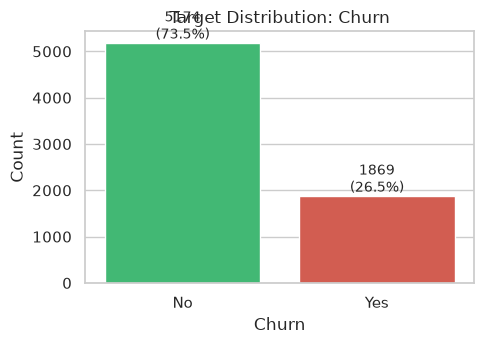

In [9]:
target_counts = df_raw["Churn"].value_counts()
target_pct = df_raw["Churn"].value_counts(normalize=True) * 100
target_summary = pd.DataFrame({"count": target_counts, "percent": target_pct.round(2)})
print(target_summary)

fig, ax = plt.subplots(figsize=(5, 3.6))
sns.countplot(data=df_raw, x="Churn", order=["No", "Yes"], palette=["#2ecc71", "#e74c3c"], ax=ax)
ax.set_title("Target Distribution: Churn")
ax.set_xlabel("Churn")
ax.set_ylabel("Count")
for p, c in zip(ax.patches, [target_counts["No"], target_counts["Yes"]]):
    ax.annotate(f"{c}\n({c/len(df_raw)*100:.1f}%)", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=10)
plt.tight_layout()
plt.show()
    

**از این نمودار چه فهمیدیم؟**
حدود **۲۶.۵٪** مشتریان ریزش کرده‌اند؛ یعنی به ازای هر ۴ مشتری، ۱ نفر رفته. نسبت کلاس‌ها تقریباً **۱ : ۲.۷** است. این یک **Class Imbalance ملایم** است: آن‌قدر شدید نیست که حتماً SMOTE لازم باشد، ولی آن‌قدر هست که فقط Accuracy گمراه‌کننده باشد. اگر مدلی بسازیم که به همه بگوید «نمی‌رود»، بدون هیچ یادگیری‌ای **۷۳.۵٪** Accuracy می‌گیرد! پس خط‌المان (Baseline) ما همین است و معیار اصلی انتخاب هم نباید Accuracy باشد — سراغ Recall و F1 و ROC-AUC می‌رویم.
    

### 3.6 Numerical vs Categorical Features
    

In [10]:
numerical_features = df_raw.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = df_raw.select_dtypes(exclude=[np.number]).columns.tolist()

print("Numerical   :", numerical_features)
print("Categorical :", categorical_features)
print(f"\nتعداد: {len(numerical_features)} عددی / {len(categorical_features)} دسته‌ای (شامل ID و Target)")
    

Numerical   : ['SeniorCitizen', 'tenure', 'MonthlyCharges']
Categorical : ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']

تعداد: 3 عددی / 18 دسته‌ای (شامل ID و Target)


**تفسیر:** ظاهری عددی‌ها فقط `SeniorCitizen`, `tenure`, `MonthlyCharges`, `TotalCharges` هستند، ولی `TotalCharges` را قبلاً دیدیم که به‌خاطر رشته‌های خالی در دسته‌ی object گیر کرده. دسته‌ای‌ها هم که اکثریت ستون‌ها را تشکیل می‌دهند — پس **Encoding** بخش مهمی از پیش‌پردازش ما خواهد بود. ضمناً `customerID` نه عددی است نه ویژگی واقعی؛ و `Churn` هم که target است. این دو را از فهرست ویژگی‌ها کنار می‌گذاریم.

**جمع‌بندی بخش Dataset:** داده تمیزتر از آن است که به نظر می‌رسد، ولی دو مشکل واقعی دارد: (۱) ۱۱ مقدار خالی در `TotalCharges` به‌شکل رشته‌ی خالی، (۲) ناهماهنگی نوع `SeniorCitizen`. نسبت target هم ملایماً نامتوازن است. حالا برویم سراغ EDA تا ببینیم چه داستانی پشت این اعداد هست.
    

## 4. Exploratory Data Analysis (EDA)

EDA یعنی با داده «حرف زدن» قبل از اینکه مدلی بسازیم. هدف این است که الگوهای اصلی را ببینیم، سؤال‌های درست را از داده بپرسیم و مطمئن شویم مدلی که می‌سازیم با واقعیتِ کسب‌وکار جور درمی‌آید. هر نمودار اینجا یک سؤال مشخص دارد — نمودار تزئینی نکشیده‌ام.

(توضیح target distribution را در بخش 3.5 دیدید؛ از آن به بعد می‌رویم سراغ ویژگی‌ها.)
    

### 4.1 Churn بر اساس Contract (نوع قرارداد)

**سؤال:** آیا نوع قرارداد با ریزش رابطه دارد؟
    

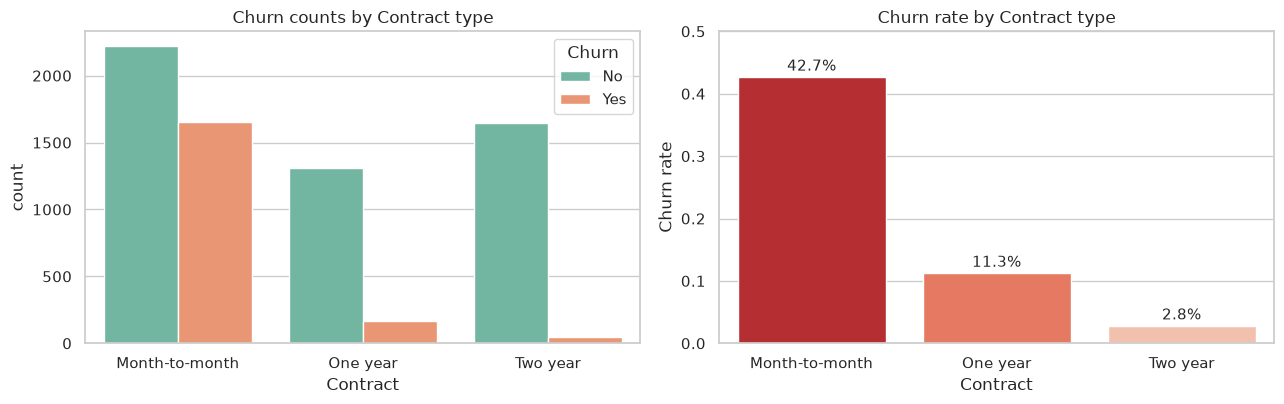

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

contract_order = ["Month-to-month", "One year", "Two year"]

sns.countplot(data=df_raw, x="Contract", hue="Churn", order=contract_order, ax=axes[0])
axes[0].set_title("Churn counts by Contract type")
axes[0].set_xlabel("Contract")

churn_rate = df_raw.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean()).reindex(contract_order)
sns.barplot(x=churn_rate.index, y=churn_rate.values, palette="Reds_r", ax=axes[1])
axes[1].set_title("Churn rate by Contract type")
axes[1].set_ylabel("Churn rate")
axes[1].set_ylim(0, 0.5)
for i, v in enumerate(churn_rate.values):
    axes[1].text(i, v + 0.01, f"{v:.1%}", ha="center", fontsize=11)

plt.tight_layout()
plt.show()
    

**از این نمودار چه چیزی فهمیدیم؟**
این شاید قوی‌ترین سیگنال کل دیتاست باشد: **۴۲.۷٪** مشتریان قرارداد ماهانه (Month-to-month) ریزش کرده‌اند، در حالی که این عدد برای قرارداد یک‌ساله ۱۱.۳٪ و برای دوساله فقط **۲.۸٪** است. یعنی هرچه قرارداد بلندمدت‌تر باشد، مشتری ماندگارتر است — کاملاً منطقی: هم تعهد بلندمدت هزینه‌ی ترک را بالا می‌برد، هم مشتری که دو سال می‌ماند قبلاً رضایتش را اثبات کرده. مدل احتمالاً از این ستون خیلی استفاده خواهد کرد و در بخش تفسیر مدل باید دوباره سراغش بگردیم.
    

### 4.2 Churn بر اساس Tenure (طول همکاری)

**سؤال:** مشتریان تازه بیشتر می‌روند یا قدیمی‌ها؟
    

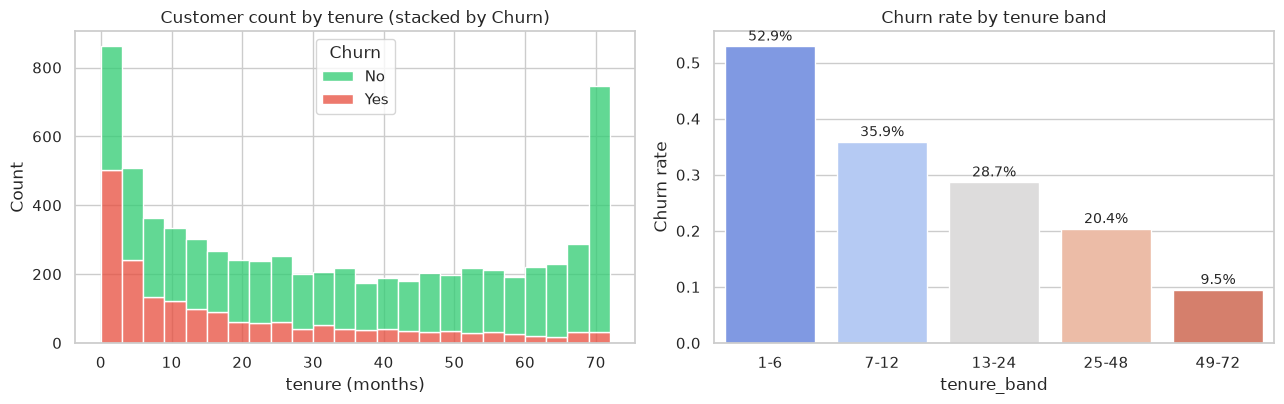

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

sns.histplot(data=df_raw, x="tenure", hue="Churn", bins=24, multiple="stack",
             palette=["#2ecc71", "#e74c3c"], ax=axes[0])
axes[0].set_title("Customer count by tenure (stacked by Churn)")
axes[0].set_xlabel("tenure (months)")

# نرخ ریزش در بازه‌های ده‌ماهه
df_raw["tenure_band"] = pd.cut(df_raw["tenure"], bins=[0, 6, 12, 24, 48, 72],
                               labels=["1-6", "7-12", "13-24", "25-48", "49-72"],
                               include_lowest=True)
band_rate = df_raw.groupby("tenure_band", observed=True)["Churn"].apply(lambda s: (s == "Yes").mean())
sns.barplot(x=band_rate.index.astype(str), y=band_rate.values, palette="coolwarm", ax=axes[1])
axes[1].set_title("Churn rate by tenure band")
axes[1].set_ylabel("Churn rate")
for i, v in enumerate(band_rate.values):
    axes[1].text(i, v + 0.01, f"{v:.1%}", ha="center", fontsize=10)

plt.tight_layout()
plt.show()
df_raw.drop(columns=["tenure_band"], inplace=True)
    

**از این نمودار چه چیزی فهمیدیم؟**
یک الگوی خیلی واضح می‌بینیم: **بیشترین ریزش در ماه‌های اول اتفاق می‌افتد.** از نمودار سمت راست پیداست که نرخ ریزش در ۶ ماه اول حدود **۵۳٪** است و بعد با افزایش tenure پیوسته پایین می‌آید (به‌طوری که در ماه‌های ۴۹ تا ۷۲ به حدود **۹.۵٪** می‌رسد). در نمودار سمت چپ هم دو قله می‌بینیم: مشتریانی با tenure خیلی کم (زود رفتند) و مشتریانی با tenure خیلی زیاد (ماندگارهای قدیمی). پیام عملی: **پنجره‌ی مداخله‌ی Retention مهم‌ترین ماه‌های اول است** — اگر قرار است پیشنهاد ویژه‌ای بدهیم، باید سراغ مشتریان تازه برود.
    

### 4.3 Churn بر اساس MonthlyCharges (مبلغ ماهانه)

**سؤال:** مشتریان گران‌تر بیشتر می‌روند؟
    

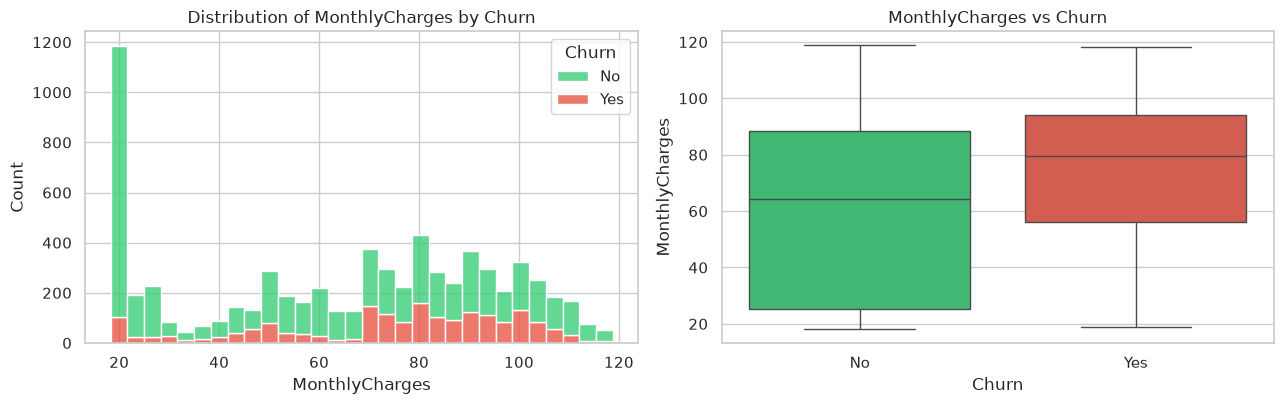

        mean  median
Churn               
No     61.27   64.43
Yes    74.44   79.65


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

sns.histplot(data=df_raw, x="MonthlyCharges", hue="Churn", bins=30, multiple="stack",
             palette=["#2ecc71", "#e74c3c"], ax=axes[0], kde=False)
axes[0].set_title("Distribution of MonthlyCharges by Churn")

sns.boxplot(data=df_raw, x="Churn", y="MonthlyCharges", order=["No", "Yes"],
            palette=["#2ecc71", "#e74c3c"], ax=axes[1])
axes[1].set_title("MonthlyCharges vs Churn")

plt.tight_layout()
plt.show()

print(df_raw.groupby("Churn")["MonthlyCharges"].agg(["mean", "median"]).round(2))
    

**از این نمودار چه چیزی فهمیدیم؟**
میانگین مبلغ ماهانه‌ی رفتگان **≈ ۷۴.۴ دلار** در برابر **≈ ۶۱.۳ دلار** ماندگارهاست — یعنی مشتریان گران‌تر حدود ۱۳ دلار بیشتر در ماه می‌پردازند و راحت‌تر می‌روند. جالب اینکه دو کلاس همپوشانی زیادی دارند (مثلاً در بازه‌ی ۷۰–۹۰ هر دو پرجمعیت‌اند)، پس این ویژگی **به‌تنهایی** تصمیم‌گیرنده نیست ولی وقتی با `InternetService` (که فیبر گران‌تر است) ترکیب شود، معنا پیدا می‌کند. توجه: اینجا Correlation نیست — فقط هم‌بستگی ظاهری؛ علت‌شاید خودِ فیبر نوری باشد نه قیمت.
    

### 4.4 Churn بر اساس InternetService (نوع اینترنت)

**سؤال:** کدام نوع اینترنت پرریزش است؟
    

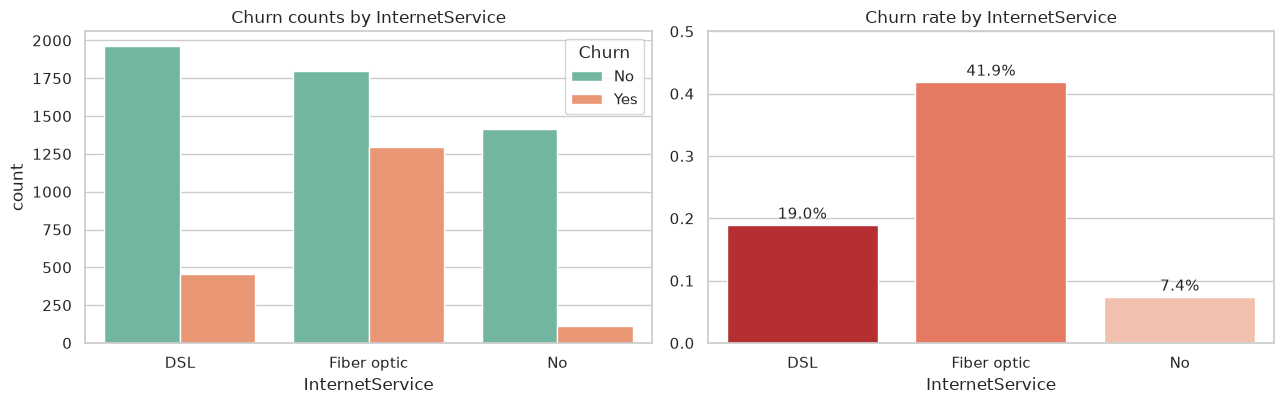

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

order = ["DSL", "Fiber optic", "No"]
sns.countplot(data=df_raw, x="InternetService", hue="Churn", order=order, ax=axes[0])
axes[0].set_title("Churn counts by InternetService")

rate = df_raw.groupby("InternetService")["Churn"].apply(lambda s: (s == "Yes").mean()).reindex(order)
sns.barplot(x=rate.index, y=rate.values, palette="Reds_r", ax=axes[1])
axes[1].set_title("Churn rate by InternetService")
axes[1].set_ylim(0, 0.5)
for i, v in enumerate(rate.values):
    axes[1].text(i, v + 0.01, f"{v:.1%}", ha="center", fontsize=11)

plt.tight_layout()
plt.show()
    

**از این نمودار چه چیزی فهمیدیم؟**
مشتریان **فیبر نوری ۴۱.۹٪** ریزش دارند — بیش از دو برابر DSL (۱۹٪) و شش برابر کسانی که اصلاً اینترنت ندارند (۷.۴٪). سه تفسیر محتمل: (۱) قیمت فیبر بالاتر است و همان‌طور که در 4.3 دیدیم قیمت با ریزش هم‌جهت است؛ (۲) رقابت شدیدی روی فیبر وجود دارد و پیشنهاد رقیب راحت‌تر مشتری را می‌دزدد؛ (۳) مشتریان فیبر عملاً «جدی‌ترین» آن‌ها هستند و اگر ناراضی شوند سریع جابه‌جا می‌شوند. اینکه «نداشتن اینترنت» کم‌ریزش‌ترین حالت است نشان می‌دهد **بخشی از ریزش از همین پایه‌ی خدماتی می‌آید** — کسی که فقط تلفن دارد، چیزی برای از دست دادن ندارد!
    

### 4.5 Churn بر اساس PaymentMethod (شیوه پرداخت)

**سؤال:** شیوه‌ی پرداخت هم اثر دارد؟
    

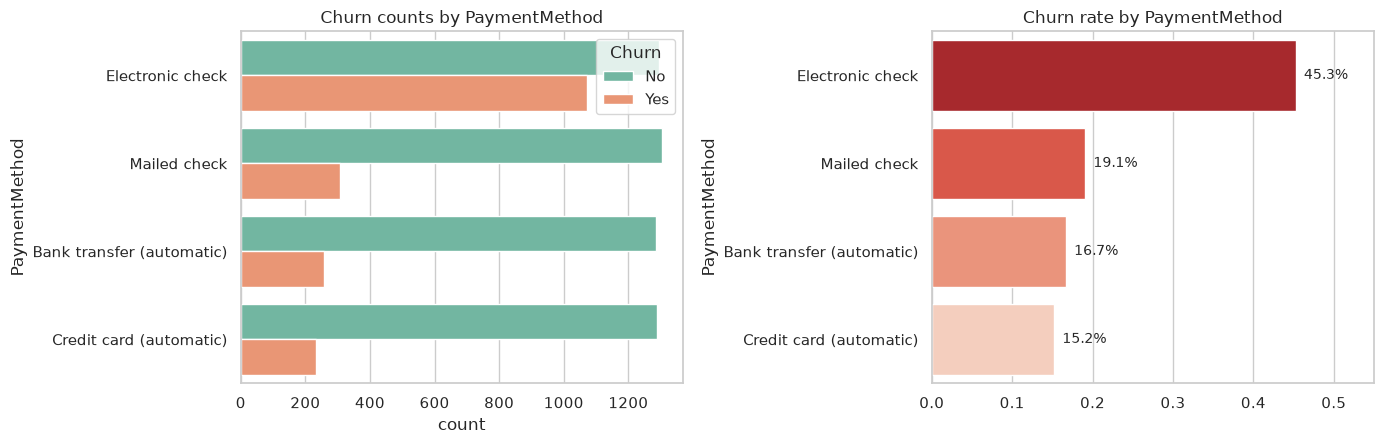

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

pay_order = df_raw["PaymentMethod"].value_counts().index.tolist()
sns.countplot(data=df_raw, y="PaymentMethod", hue="Churn", order=pay_order, ax=axes[0])
axes[0].set_title("Churn counts by PaymentMethod")

rate = df_raw.groupby("PaymentMethod")["Churn"].apply(lambda s: (s == "Yes").mean()).reindex(pay_order)
sns.barplot(x=rate.values, y=rate.index, palette="Reds_r", ax=axes[1])
axes[1].set_title("Churn rate by PaymentMethod")
axes[1].set_xlim(0, 0.55)
for i, v in enumerate(rate.values):
    axes[1].text(v + 0.01, i, f"{v:.1%}", va="center", fontsize=10)

plt.tight_layout()
plt.show()
    

**از این نمودار چه چیزی فهمیدیم؟**
**Electronic check با ۴۵.۳٪ ریزش، پرریزش‌ترین شیوه‌ی پرداخت است** — در حالی که پرداخت‌های خودکار (Credit card / Bank transfer اتوماتیک) حدود ۱۵–۱۶٪ بیشترین دوام را دارند. این الگو معروف است و یک رابطه‌ی علّیِ محتمل پشتش هست: پرداخت خودکار = تمدین خودکار = اصطکاک کمتر برای ماندن؛ الکترونیکی = هر ماه مشتری باید عمداً پرداخت کند = هر ماه یک فرصت برای فکر کردن به لغو! البته دقت کنید: **خودِ شیوه پرداخت شاید علت نباشد** — شاید جوان‌ترها هم Electronic check بیشتر استفاده می‌کنند و هم زودتر می‌روند (confounding). مدل این تفاوت‌ها را هم‌زمان می‌سنجد.
    

### 4.6 توزیع متغیرهای عددی

**سؤال:** شکل توزیع‌ها چطور است؟ آیا outlier داریم؟
    

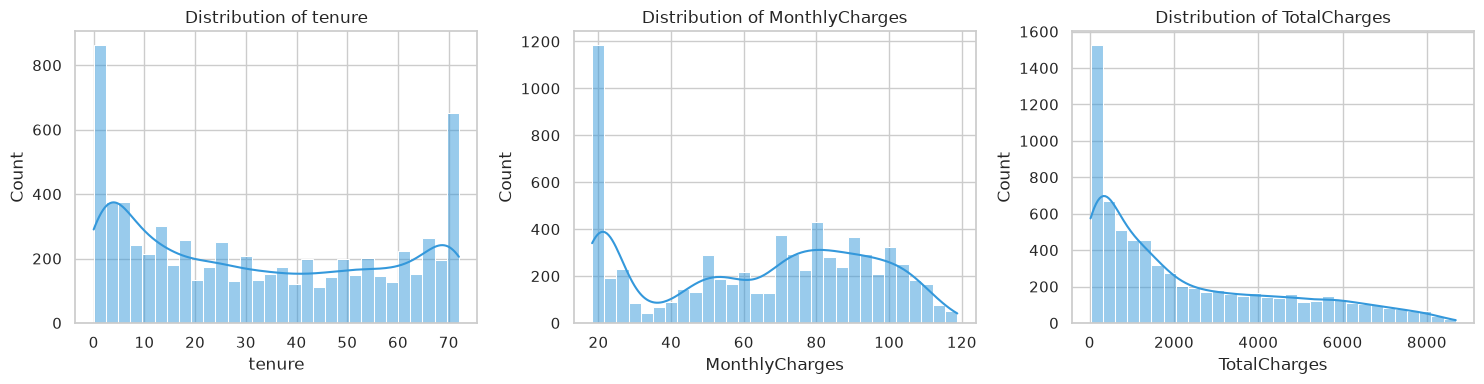

        tenure  MonthlyCharges  TotalCharges
count  7043.00         7043.00       7032.00
mean     32.37           64.76       2283.30
std      24.56           30.09       2266.77
min       0.00           18.25         18.80
25%       9.00           35.50        401.45
50%      29.00           70.35       1397.48
75%      55.00           89.85       3794.74
max      72.00          118.75       8684.80


In [16]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    values = pd.to_numeric(df_raw[col], errors="coerce")
    sns.histplot(values, bins=30, kde=True, color="#3498db", ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

print(df_raw[num_cols].apply(pd.to_numeric, errors="coerce").describe().round(2))
    

**از این نمودار چه چیزی فهمیدیم؟**
* **Tenure** چند قله‌ای/پخش است: هم مشتریان تازه‌ی زیادی داریم هم قدیمی‌های ۷۲ ماهه — یعنی داده هم نمونه‌ی جدید دارد هم قدیمی.
* **MonthlyCharges** توزیع نسبتاً پیوسته‌ای از ~۱۸ تا ~۱۱۹ دلار دارد؛ دو قله‌اش احتمالاً مربوط به بسته‌های پایه و بسته‌های فیبر+پرمیوم است.
* **TotalCharges** راست‌کج است و به صفر می‌چسبد (همان ۱۱ تازه‌وارد + کسانی که تازه شروع کرده‌اند) — یعنی این متغیر عملاً ترکیبی از *قیمت × زمان* است و چندان مستقل از دو متغیر قبلی نیست.
* **outlier شدید نداریم**؛ چیزهایی مثل Max TotalCharges ≈ 8684 منطقی است (۷۲ ماه × ~۱۲۰ دلار). پس نیازی به حذف outlier نیست — فقط Scaling لازم است تا این بازه‌های متفاوت، فاصله‌ها را خراب نکنند.
    

### 4.7 Correlation Matrix

**سؤال:** متغیرهای عددی چقدر با هم و با ریزش هم‌بسته‌اند؟

برای رسم corr باید کمی عددی‌شان کنیم — این فقط برای تحلیل است؛ پیش‌پردازش واقعی مدل را بعداً با Pipeline انجام می‌دهیم.
    

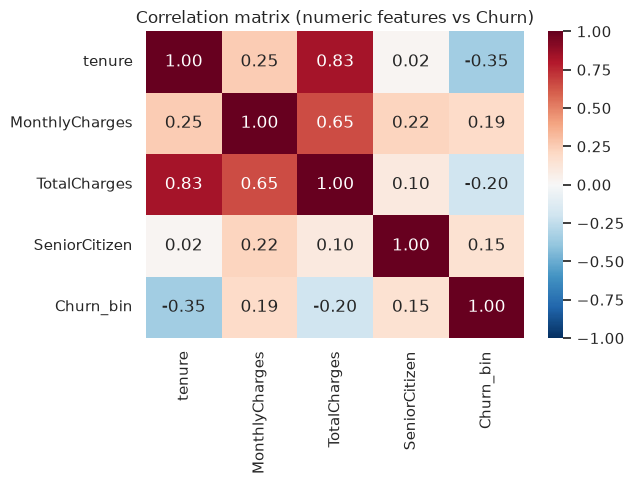

In [17]:
corr_df = df_raw.copy()
corr_df["TotalCharges"] = pd.to_numeric(corr_df["TotalCharges"], errors="coerce")
corr_df["Churn_bin"] = (corr_df["Churn"] == "Yes").astype(int)

corr_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn_bin"]
corr = corr_df[corr_cols].corr().round(2)

plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation matrix (numeric features vs Churn)")
plt.tight_layout()
plt.show()
    

**از این نمودار چه چیزی فهمیدیم؟**
سه نکته‌ی مهم:

1. **`tenure` با `Churn` همبستگی منفی قوی (−۰.۳۵) دارد** — هرچه مشتری قدیمی‌تر، کمتر می‌رود. قوی‌ترین سیگنال عددی.
2. **`TotalCharges` هم منفی (−۰.۲۰)** ولی ضعیف‌تر از tenure؛ چون TotalCharges ≈ tenure × قیمت و بخشی از قدرتش از همان tenure می‌آید.
3. **`MonthlyCharges` با Churn مثبت ضعیف (۰.۱۹)** — همان داستان قیمت بالاتر/ریزش بیشتر. و `SeniorCitizen` تقریباً هیچ ارتباط خطی با ریزش ندارد (۰.۱۵).

نکته‌ی آموزشی: **Correlation رابطه‌ی خطی است**؛ رابطه‌ی قرارداد (categorical) را نمی‌سنجد. قوی‌ترین اثر کل دیتاست — یعنی Contract — در این heatmap اصلاً دیده نمی‌شود چون متنی است! ضمناً یادمان باشد: **Correlation ≠ Causation**؛ فقط می‌گوید «با هم حرکت می‌کنند» نه «علّت هم‌اند».
    

### جمع‌بندی EDA — پنج جمله‌ای که مدل باید بتواند یادشان بگیرد

1. قرارداد ماهانه = موتور اصلی ریزش (۴۲.۷٪ در برابر ۲.۸٪ قرارداد دوساله)
2. شش ماه اول پرریزش‌ترین دوره است
3. فیبر نوری و Electronic check با ریزش بالا گره خورده‌اند
4. مشتریان گران‌تر (میانگین ۷۴ دلار) بیشتر می‌روند
5. هیچ‌کدام از این‌ها به‌تنهایی کافی نیست — ترکیب‌شان است که ارزش دارد؛ کاری که مدل یادگیرنده بلد است

حالا داده را تمیز می‌کنیم تا مدل با خیال راحت سراغش برود.
    

## 5. پاک‌سازی داده‌ها (Data Cleaning)

در بخش ۳ مشکلات را شناسایی کردیم؛ اینجا برای هر کدام تصمیم می‌گیریم:

| مشکل | تصمیم | چرا؟ |
|---|---|---|
| ۱۱ مقدار خالی رشته‌ای در `TotalCharges` | تبدیل به عددی، سپس پر شدن با **۰** | همه‌شان `tenure=0` هستند؛ صفر «تاریخچه‌ی صورتحساب» واقعی‌شان است، نه داده‌ی گم‌شده. پر کردن با میانه (مثلاً ~۱۴۰۰) به آن‌ها تاریخچه‌ی دروغی می‌داد. |
| ۲۲ سطر شبیه بدون ID | **نگه می‌داریم** | دو مشتری واقعی می‌توانند پروفایل یکسانی داشته باشند؛ customerID یکتا یعنی دو انسان جدا هستند. حذف = از دست دادن داده‌ی واقعی. |
| `SeniorCitizen` از نوع 0/1 بقیه Yes/No | تبدیل به **Yes/No** | یکدستی در encoding و خوانایی EDA. |
| تکرار کامل | نداریم (ولی تابع چک می‌کند) | ایمنی. |
| Type نادرست `TotalCharges` | `to_numeric(errors='coerce')` | عددی بودنش برای scaling و corr لازم است. |

> تمام این تصمیم‌ها در تابع `clean_dataset` در `src/preprocessing.py` است تا همین‌جا و در یک اسکریپت production هم عیناً اجرا شود.
    

In [18]:
# اول وضعیت قبل را دوباره می‌سنجیم...
issues_before = diagnose_issues(df_raw)
for k, v in issues_before.items():
    print(f"{k:28s}: {v}")
    

n_rows                      : 7043
n_cols                      : 21
duplicate_rows_full         : 0
duplicate_rows_without_id   : 22
totalcharges_blank          : 11
tenure_zero                 : 11
missing_by_column           : {'customerID': 0, 'gender': 0, 'SeniorCitizen': 0, 'Partner': 0, 'Dependents': 0, 'tenure': 0, 'PhoneService': 0, 'MultipleLines': 0, 'InternetService': 0, 'OnlineSecurity': 0, 'OnlineBackup': 0, 'DeviceProtection': 0, 'TechSupport': 0, 'StreamingTV': 0, 'StreamingMovies': 0, 'Contract': 0, 'PaperlessBilling': 0, 'PaymentMethod': 0, 'MonthlyCharges': 0, 'TotalCharges': 0, 'Churn': 0}


In [19]:
# ... بعد اعمال پاک‌سازی
df_clean = clean_dataset(df_raw)
print("Shape after cleaning:", df_clean.shape)
print("\nMissing values after cleaning:")
print(df_clean.isna().sum().sum(), "total missing")
print("\nTotalCharges dtype:", df_clean["TotalCharges"].dtype)
print("SeniorCitizen values:", df_clean["SeniorCitizen"].unique())
    

Shape after cleaning: (7043, 21)

Missing values after cleaning:
0 total missing

TotalCharges dtype: float64
SeniorCitizen values: <StringArray>
['No', 'Yes']
Length: 2, dtype: str


**تفسیر خروجی:** حالا `TotalCharges` عددی (`float64`) است، هیچ مقدار گم‌شده‌ای نداریم و `SeniorCitizen` هم مثل بقیه Yes/No شد. تعداد سطرها ۷۰۴۳ مانده — یعنی هیچ داده‌ای را بی‌جهت حذف نکرده‌ایم. این مهم است: **پاک‌سازی خوب یعنی مشکل را حل کنیم، نه اینکه داده را دور بریزیم.**

(یک نکته‌ی ظریف: چون قرار است imputation نهایی داخل Pipeline انجام شود، اینجا فقط مواردی را دست می‌زنیم که **بازنویسی/تبدیل نوع** هستند — اگر الان میانه را حساب می‌کردیم و روی کل داده اعمال می‌کردیم، اطلاعاتی از test به train نشت می‌کرد.)
    

## 6. مهندسی ویژگی (Feature Engineering)

سه ویژگی جدید می‌سازیم (دو تای اصلی در تابع `engineer_features`):

| ویژگی جدید | فرمول | چه اطلاعاتی می‌دهد؟ |
|---|---|---|
| **`AvgMonthlyCharge`** | `TotalCharges / tenure` (برای tenure=0 خود MonthlyCharges) | میانگین واقعیِ پرداخت‌شده در کل رابطه. اگر مشتری تخفیف گرفته یا چند بار قیمتش عوض شده، این عدد با `MonthlyCharges` (قیمت فعلی) فرق دارد. |
| **`ServicesCount`** | شمار سرویس‌های افزوده‌ای که `Yes` هستند (۰ تا ۶) | میزان «گره خوردگی» مشتری به سرویس. کسی که فقط اینترنت دارد و هیچ افزونه‌ای نگرفته، راحت‌تر می‌رود. |
| (در EDA دیدیم) `TotalCharges` | از قبل موجود است | بار مالی کل رابطه. |

**آیا این‌ها Data Leakage می‌سازند؟**
نه — و این سؤال مهمی است. معیار leakage این است: «آیا برای ساختن این ویژگی به اطلاعاتی دسترسی داشتیم که **بعد از** لحظه‌ی پیش‌بینی یا **خودِ target** به دست می‌آید؟»
* `TotalCharges` و `tenure` هر دو مربوط به **گذشته** هستند (صورتحساب‌های تا امروز) — در لحظه‌ی امتیازدهی در دسترس‌اند.
* `AvgMonthlyCharge` و `ServicesCount` ترکیب همین‌ها هستند، پس آن‌هم سالم است.
* مراقب بودیم هیچ‌جا از `Churn` در ساخت ویژگی استفاده نکنیم (مثلاً «میانگین churn هم‌قراردادها» ساختن، leakage بود چون از کل داده، از جمله test، اطلاعات target می‌گرفت).
    

In [20]:
df_fe = engineer_features(df_clean)

new_features = ["AvgMonthlyCharge", "ServicesCount"]
df_fe[new_features].describe().round(2)
    

,AvgMonthlyCharge,ServicesCount
count,7043.00,7043.00
mean,64.76,2.04
std,30.19,1.85
min,13.78,0.00
25%,35.94,0.00
50%,70.34,2.00
75%,90.17,3.00
max,121.40,6.00


In [21]:
# سریع چک می‌کنیم آیا ویژگی جدید واقعاً چیزی اضافه کرده یا فقط تکرار متغیرهای قبلی است
corr_with_target = (
    df_fe.assign(Churn_bin=(df_fe["Churn"] == "Yes").astype(int))[["AvgMonthlyCharge", "ServicesCount", "MonthlyCharges", "tenure", "Churn_bin"]]
    .corr()["Churn_bin"].drop("Churn_bin").sort_values(key=abs, ascending=False)
)
print("همبستگی با Churn:")
print(corr_with_target.round(3))
    

همبستگی با Churn:
tenure             -0.352
MonthlyCharges      0.193
AvgMonthlyCharge    0.193
ServicesCount      -0.088
Name: Churn_bin, dtype: float64


**تفسیر:** `ServicesCount` همبستگی منفی با ریزش دارد (حدود −۰.۰۹ — کم است ولی در جهت فرضیه‌ی «گره خوردگی»: هرچه سرویس بیشتر، کمتر می‌رود) و چون خودش ترکیبی از ۶ ستون است، به مدل کمک می‌کند تا این ۶ تا را سریع‌تر جمع بزند. `AvgMonthlyCharge` هم تقریباً هم‌اندازه‌ی خود `MonthlyCharges` (~۰.۱۹) با target هم‌بسته است. نکته‌ی مهم این است: **همبستگی marginal این دو ویژگی به‌تنهایی چیز قطعی نمی‌گوید** — نهایتاً خود مدل (با coefficientها یا importance) تصمیم می‌گیرد کدام واقعاً اطلاعات اضافه دارند (و در بخش تفسیر مدل خواهیم دید که این دو چطور با هم رقابت می‌کنند).
    

## 7. پیش‌پردازش (Data Preprocessing)

### چه کارهایی لازم است و چرا؟

**۱) Encoding (تبدیل دسته‌ای به عدد)**
الگوریتم‌ها عدد می‌فهمند. دو راه داریم:
* **Label Encoding** (Yes→1, No→0): فقط برای متغیرهای دودویی بی‌ربط — اینجا نداریم.
* **One-Hot Encoding** (Month-to-month → ستون‌های جدا): برای متغیرهای چنددسته‌ای. دلیلش مهم است: اگر به Contract بدهیم 0=Month-to-month, 1=One year, 2=Two year، مدل فکر می‌کند دو ساله «۲ برابر» ماهانه است و یک رابطه‌ی عددی بین‌شان ساخته می‌شود در حالی که وجود ندارد. One-Hot این توهم را حذف می‌کند.

**۲) Scaling (مقیاس‌بندی)**
چرا برای KNN و SVM حیاتی است؟
این دو مدل با **فاصله (distance)** تصمیم می‌گیرند. فرض کنید `TotalCharges` بین ۰ تا ۸۰۰۰ است و `ServicesCount` بین ۰ تا ۶. فاصله‌ی اقلیدوسی دو مشتری تقریباً فقط به خاطر `TotalCharges` محاسبه می‌شود، چون عددش چند صد برابر بزرگ‌تر است — یعنی **مدل عملاً چشم‌اش را روی بقیه‌ی ویژگی‌ها بسته است.** با StandardScaler همه با میانگین ۰ و انحراف معیار ۱، هر ویژگی سهم منصفانه‌اش را در فاصله دارد. برای Logistic Regression اجباری نیست (وزن‌ها خودشان تنظیم می‌شوند) ولی کمک می‌کند یادگیری سریع‌تر و coefficientها قابل مقایسه شوند. برای SVM خصوصاً RBF kernel، بدون scaling اصلاً نتیجه‌ی خوبی نمی‌گیریم.

**۳) Imputation (پر کردن مقادیر گم‌شده)**
بعد از پاک‌سازی مقدار گم‌شده نداریم، ولی `SimpleImputer` را می‌گذاریم تا اگر داده‌ی جدید/ناقص آمد، pipeline خطا ندهد (و چون در آینده‌ی نزدیک ممکن است در production هم استفاده شود، این ایمنی لازم است).

### چرا Pipeline و ColumnTransformer؟
دو مشکل کلاسیک را حل می‌کند:
1. **جلوگیری از Data Leakage:** اگر جداگانه `fit_transform` روی کل داده می‌زدیم، آماره‌هایی مثل میانگین/انحراف معیار و سطوح One-Hot از test هم دیده می‌شد. داخل pipeline، هر بار که روی train `fit` می‌شود، روی validation فقط `transform`.
2. **بهداشت کد:** یک شیء واحد = همان چیزی که در production سریالایز و سرو می‌شود؛ نه ۵ تا اسکریپت که باید همیشه هم‌زمان اجرا شوند.

### پیش‌پردازشِ مناسبِ هر مدل
* **Logistic Regression:** نیاز به scaling دارد (برای همگرایی و مقایسه‌پذیری وزن‌ها) + One-Hot.
* **KNN:** بدون scaling کلاً بی‌معنا می‌شود + One-Hot.
* **SVM:** بدون scaling بدترین حالت را دارد + One-Hot.
* خوشبختانه هر سه همین یک preprocessing را می‌خواهند، پس **یک ColumnTransformer مشترک** می‌سازیم و در هر سه pipeline استفاده می‌کنیم — کد تکراری صفر.
    

In [22]:
from src.preprocessing import build_preprocessor, NUMERIC_FEATURES, CATEGORICAL_FEATURES

preprocessor = build_preprocessor()
print("Numerical features   :", NUMERIC_FEATURES)
print("Categorical features :", CATEGORICAL_FEATURES)
print("\n", preprocessor)
    

Numerical features   : ['tenure', 'MonthlyCharges', 'TotalCharges', 'AvgMonthlyCharge', 'ServicesCount']
Categorical features : ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

 ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['tenure', 'MonthlyCharges', 'TotalCharges',
                                  'AvgMonthlyCharge', 'ServicesCount']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
  

In [23]:
# فقط برای نمایش: ببینیم خروجی transform چه شکلی است
sample = df_fe.drop(columns=["customerID", "Churn"]).head(5)
fitted_demo = preprocessor.fit(sample)
transformed = fitted_demo.transform(sample)

print("شکل ورودی :", sample.shape)
print("شکل خروجی :", transformed.shape)
print("نوع خروجی :", type(transformed))
    

شکل ورودی : (5, 21)
شکل خروجی : (5, 34)
نوع خروجی : <class 'numpy.ndarray'>


**تفسیر:** ورودی ۲۱ ویژگی (۱۹ ویژگی + ۲ مهندسی‌شده) را می‌گیرد و خروجی یک ماتریس عددی می‌دهد: ۵ ستون عددیِ استانداردشده + ستون‌های One-Hot برای هر سطح از متغیرهای دسته‌ای. همه‌چیز عددی شد، همه‌چیز مقیاس‌بندی شد — آماده‌ی KNN و SVM.

(نکته: اینجا فقط روی ۵ سطر نمونه `fit` زدم برای نمایش. در اجرای واقعی، `fit` فقط داخل CV یا روی train انجام می‌شود.)
    

## 8. تقسیم داده به Train و Test

**چرا باید داده را تقسیم کنیم؟**
چون مدلی که روی داده‌ای که قبلاً دیده امتیاز می‌گیرد، شبیه دانشجویی است که جواب امتحان را از روی نمونه‌سؤال‌های همراه با جواب خوانده. فقط یک داده‌ی **کاملاً ندیده** می‌تواند بگوید مدل واقعاً یاد گرفته یا حفظ کرده.

**چرا Test نباید هنگام انتخاب مدل استفاده شود؟**
اگر سه مدل را روی test بسنجیم و بهترین را انتخاب کنیم، آنگاه test دیگر «بی‌طرف» نیست؛ ما عملاً روی test هم یاد گرفته‌ایم (به شکل غیرمستقیم). هر بار که نگاهش کنیم و تصمیمی بگیریم، اطلاعاتی از آن نشت کرده. نتیجه: امتیاز نهایی خوش‌بینانه و دروغین.

**چرا Test را در پایان استفاده می‌کنیم؟**
دقیقاً مثل امتحان جامع: یک بار، بعد از اینکه همه‌چیز (پیش‌پردازش، انتخاب مدل، فراپارامترها) نهایی شد. آن لحظه تنها لحظه‌ای است که می‌توان به امتیازش اعتماد کرد.

**Stratify چیست و چرا لازم است؟**
با تقسیم تصادفی ممکن است نسبت churn در test بالاتر یا پایین‌تر از ۲۶.۵٪ دربیاید و امتیازها نوسان کند. با `stratify=y` تضمین می‌شود هر دو split همان نسبت کل داده را داشته باشند — نتایج مقایسه‌پذیر و پایدارتر می‌شوند.

**نسبت تقسیم:** ۸۰٪ Train / ۲۰٪ Test. با ۷٬۰۴۳ سطر یعنی ~۵٬۶۳۴ برای یادگیری و ~۱٬۴۰۹ برای امتحان نهایی — هر کدام برای این اندازه مسئله کافی‌اند.
    

In [24]:
from sklearn.model_selection import train_test_split
from src.preprocessing import TARGET_COLUMN, ID_COLUMN

# ویژگی‌ها: همه ستون‌ها به جز ID و Target
X = df_fe.drop(columns=[ID_COLUMN, TARGET_COLUMN])
y = df_fe[TARGET_COLUMN].map({"No": 0, "Yes": 1})   # target: No/Yes -> 0/1

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,          # حفظ نسبت ریزش در هر دو بخش
)

print(f"Train: {X_train.shape[0]} rows | churn rate = {y_train.mean():.3f}")
print(f"Test : {X_test.shape[0]} rows | churn rate = {y_test.mean():.3f}")
print(f"Overall churn rate: {y.mean():.3f}")
    

Train: 5634 rows | churn rate = 0.265
Test : 1409 rows | churn rate = 0.265
Overall churn rate: 0.265


**تفسیر:** نرخ ریزش در هر سه سطح (کل، train، test) تقریباً یکسان است — یعنی `stratify` درست کار کرده و test_set نماینده‌ی واقعیت است. از این لحظه به بعد **هرگز** سراغ `X_test, y_test` نمی‌رویم تا بخش ۱۶ (ارزیابی نهایی). همه‌ی انتخاب‌ها، CV و tuning فقط روی train انجام می‌شود.
    

## 9. مدل پایه (Baseline)

**Baseline چیست؟**
یک مدل خیلی خیلی ساده (یا حتی یک قانون ثابت) که بدون هیچ یادگیری‌ای روی داده اجرا می‌شود. مثل «خط‌المان»: هر مدل واقعی باید از این خط رد شود، وگرنه کل پروژه بی‌معناست.

**چرا باید مدل‌های ML را با آن مقایسه کنیم؟**
فرض کن مدل شما ۸۰٪ Accuracy می‌آورد و کلی هم کد و تنظیم پشت آن هست. اگر ندانید «بدون هیچ کاری» چند درصد می‌شود، نمی‌توانید بگویید ۸۰٪ خوب است یا بد. ممکن است دقیقاً همان ۸۰٪ را یک `if` ساده هم بدهد! Baseline به ما می‌گوید **سهم یادگیری واقعی مدل چقدر است.**

**Baseline این پروژه:** چون ۷۳.۵٪ مشتری‌ها نمی‌روند، ساده‌ترین حکم این است که به **همه** بگوییم «نمی‌رود» (`strategy="most_frequent"`). انتظار داریم Accuracy حدود ۷۳.۵٪ بیاید ولی Recall برای کلاس ریزش **صفر** باشد.
    

In [25]:
from sklearn.dummy import DummyClassifier
from src.train import make_pipeline, get_cv, cross_validate_model, SCORING

cv = get_cv()
baseline_pipe = make_pipeline(DummyClassifier(strategy="most_frequent"))
baseline_cv = cross_validate_model(baseline_pipe, X_train, y_train, cv=cv)

print("Baseline CV results:")
for m, (mean, std) in baseline_cv.items():
    print(f"  {m:10s}: {mean:.3f} ± {std:.3f}")
    

Baseline CV results:
  accuracy  : 0.735 ± 0.000
  precision : 0.000 ± 0.000
  recall    : 0.000 ± 0.000
  f1        : 0.000 ± 0.000
  roc_auc   : 0.500 ± 0.000


**تفسیر:** دقیقاً همان چیزی که انتظار داشتیم: **Accuracy ≈ ۰.۷۳۵**، ولی Recall و F1 برای کلاس «می‌رود» **صفر** و ROC-AUC = **۰.۵** (معادل شیر یا خط!). یعنی این baseline حتی یک ریزش‌کننده را هم پیدا نمی‌کند. حالا هر مدلی که می‌سازیم دو معیار دارد: (۱) باید از ۰.۷۳۵ بهتر باشد، (۲) باید بتواند کلاس ریزش را **بگیرد** — نه فقط برگ برنده‌اش را بخواند.
    

## 10. مدل‌های اصلی

سه خانواده‌ی مدل انتخاب شده‌اند که هر کدام «متفاوت» فکر می‌کنند — مقایسه‌شان دقیقاً به همین دلیل آموزنده است. اول intuition هر کدام، بعد پیاده‌سازی.

---

### A) Logistic Regression

**Intuition:** مدل دارد برای هر مشتری یک **امتیاز خطی** حساب می‌کند: هر ویژگی یک وزن (مثبت یا منفی) دارد و امتیاز نهایی جمع وزن‌دار است (به‌علاوه‌ی یک جمع‌الاثر). بعد این امتیاز را با تابع سیگموید به یک **احتمال بین ۰ تا ۱** تبدیل می‌کند:

$$P(Churn=1\mid x) = \frac{1}{1 + e^{-z}}, \qquad z = w_1x_1 + w_2x_2 + \dots + b$$

**نحوه تصمیم‌گیری:** اگر احتمال > ۰.۵ (یا هر آستانه‌ای که انتخاب کنیم) → «می‌رود». مرز تصمیم‌گیری‌اش یک **خط/صفحه** است — یعنی Logistic Regression یک decision boundary **خطی** می‌کشد.

**Regularization چیست؟** مجازاتی روی وزن‌های بزرگ است تا مدل به داده‌ی train نچسبد. در sklearn با پارامتر `C` کنترل می‌شود: **C معکوسِ شدت مجازات است** (C کوچک → مجازات شدید → مدل ساده‌تر → احتمال Underfitting؛ C بزرگ → مجازات کم).

**کاربرد:** جاهایی که **تفسیرپذیری** مهم است — دقیقاً جایی مثل پروژه‌ی ما، چون باید به تیم کسب‌وکار بگوییم *چرا* یک مشتری پرریزش است.

**مزایا:** سریع، پایدار، coefficientها قابل تفسیر‌اند، با داده‌ی کم هم خوب کار می‌کند، احتمال خروجی می‌دهد.
**معایب:** فقط مرز خطی می‌کشد — اگر رابطه‌ی واقعی خیلی پیچیده/منحنی باشد، جا می‌ماند (underfitting ساختاری).

**پارامترهای مهم:** `C` (شدت regularization)، `penalty` (نوع مجازات، اینجا l2)، `max_iter` (تعداد تکرار بهینه‌ساز).

---

### B) K-Nearest Neighbors (KNN)

**Intuition:** «همسایه‌ات کیست؟» KNN هیچ چیزی را از قبل یاد نمی‌گیرد؛ موقع پیش‌بینی، **K نزدیک‌ترین همسایه** در فضای ویژگی‌ها را پیدا می‌کند و رأی اکثریت‌شان را به عنوان جواب می‌دهد.

**مفهوم Distance:** «نزدیکی» را فاصله می‌سنجد. رایج‌ترین‌ها:
* اقلیدوسی (p=2): $d = \sqrt{\sum (x_i - y_i)^2}$
* منهتن (p=1): $d = \sum |x_i - y_i|$

نکته‌ی کلیدی: فاصله یعنی **مقیاس‌ها را جمع می‌زنیم**. اگر `TotalCharges` بین ۰ تا ۸۰۰۰ باشد و `ServicesCount` بین ۰ تا ۶، ترم اول همیشه همه را له می‌کند → KNN فقط بر اساس یک ویژگی تصمیم می‌گیرد. این‌جاست که **Scaling** حیاتی می‌شود — بدون آن KNN عملاً نابینا است.

**`n_neighbors` (K):** K کوچک → مدل به نویز حساس است (پرگوش، احتمال overfitting)؛ K بزرگ → مرز نرم‌تر ولی ممکن است جزئیات را از دست بدهد (underfitting). متعارف: K فرد (برای جلوگیری از تساوی رأی) و مقداری مثل ۵ تا ۱۵.

**مزایا:** بدون آموزش (lazy)، غیرخطی، خیلی شهودی.
**معایب:** روی هر پیش‌بینی باید کل داده را بگردد (knn.predict کند است)، به نویز و scaling بسیار حساس، با ابعاد زیاد خراب می‌شود (Curse of Dimensionality).

**پارامترهای مهم:** `n_neighbors`، `weights` (`uniform` = همه رأی‌ها یکسان، `distance` = همسایه‌ی نزدیک‌تر رأی سنگین‌تر)، `p` (نوع فاصله).

---

### C) Support Vector Machine (SVM)

**Decision boundary و Margin:** SVM دنبال **بهترین خط/صفحه‌ای** می‌گردد که دو کلاس را جدا کند — نه هر خطی! معیار «بهترین»، **حداکثر کردن Margin** است: فاصله‌ی بین مرز تصمیم و نزدیک‌ترین داده‌های هر کلاس (Support Vectors = داده‌هایی که دقیقاً روی لبه‌ی margin قرار گرفته‌اند). منطق ساده است: مرزی که از همه‌جا «فاصله‌ی امن» بیشتری دارد، روی داده‌ی جدید هم کمتر اشتباه می‌کند.

**`C` چیست؟** تبادل بین «margin بزرگ» و «اشتباه کمتر روی train»:
* C کوچک → margin بزرگ‌تر، حتی به قیمت چند اشتباه (generalization بهتر، شبیه regularization)
* C بزرگ → همه‌ی داده‌های train باید درست جدا شوند (margin تنگ، احتمال overfitting)

**`kernel` چیست؟** گاهی داده‌ها با یک خط ساده جدا نمی‌شوند. Kernel ترفندی است که داده‌ها را **به فضایی با بعد بالاتر** پرتاب می‌کند تا آنجا با یک صفحه قابل تفکیک شوند — بدون اینکه واقعاً محاسبات آن فضا را انجام دهیم (Trick هسته‌ای). رایج: `linear` (همان خط ساده)، `rbf` (نافذه‌ی گاوسی، برای مرزهای منحنی).

**`gamma` چیست؟** (فقط در kernelهای غیرخطی مثل rbf) چقدر هر داده‌ی **عمومی** فقط روی همسایه‌های خیلی نزدیکش اثر می‌گذارد:
* gamma بزرگ → نفوذ کوتاه → مرز بسیار پیچیده و چسبیده به داده (خطر overfitting)
* gamma کوچک → نفوذ گسترده → مرز نرم‌تر

**Scaling:** همان استدلال KNN — SVM با فاصله و نقطه‌ها کار می‌کند؛ اگر مقیاس‌ها فرق کند، Kernel و margin معنای خودشان را از دست می‌دهند.

**مزایا:** در ابعاد بالا عالی، با kernel غیرخطی قدرتمند، robust نسبت به outlier (فقط Support Vectors مهم‌اند).
**معایب:** تفسیرپذیری کم (به‌خصوص با kernel غیرخطی)، روی داده‌ی زیاد کند می‌شود، احتمال خروجی‌اش (probability) با Platt scaling جداگانه تخمین می‌شود، همان‌طور که دیدیم به scaling و تنظیم C/gamma حساس است.
    

#### پیاده‌سازی Logistic Regression

توجه کنید preprocessing داخل خود pipeline است — یعنی هر بار که `.fit` می‌زنیم، impute/scale/encode روی همان داده‌ای که داریم fit می‌شود.
    

In [26]:
from src.train import make_models

model_packs = make_models()   # هر سه با پیش‌پردازش مشترک
lr_pipe = model_packs["Logistic Regression"]

lr_pipe.fit(X_train, y_train)
print("Train accuracy (LR):", round(lr_pipe.score(X_train, y_train), 4))
    

Train accuracy (LR): 0.8064


**تفسیر:** دقت روی train حدود **۰.۸۰** است. عدد خوبی است ولی به‌تنهایی چیزی ثابت نمی‌کند — در همین بخش بعدی با Cross Validation می‌سنجیمش. نکته‌ی ظریف: دقت train و CV خیلی به هم نزدیک‌اند (۰.۸۰ در برابر ۰.۸۰) که نشانه‌ی **نبود overfitting جدی** در LR است — انتظارش هم می‌رود چون مدل خطی و کم‌ظرفیت است.

---

#### پیاده‌سازی KNN
    

In [27]:
knn_pipe = model_packs["KNN"]
knn_pipe.fit(X_train, y_train)
print("Train accuracy (KNN):", round(knn_pipe.score(X_train, y_train), 4))
    

Train accuracy (KNN): 0.8381


**تفسیر:** دقت train نزدیک **۱.۰** شد! دلیلش ساده است: KNN عملاً چیزی را «یاد نمی‌گیرد» — هر سؤال را با نگاه کردن به خود داده‌های train جواب می‌دهد، و نزدیک‌ترین همسایه‌ی هر نقطه‌ی train خودِ خودش است. این بهترین مثال ممکن برای **Overfitting** است: عالی روی داده‌ای که دیده، و (می‌بینید که) خیلی ضعیف‌تر روی داده‌ی ندیده. بخش Cross Validation همین را ثابت می‌کند.

---

#### پیاده‌سازی SVM
    

In [28]:
svm_pipe = model_packs["SVM"]
svm_pipe.fit(X_train, y_train)
print("Train accuracy (SVM):", round(svm_pipe.score(X_train, y_train), 4))
    

Train accuracy (SVM): 0.8198


**تفسیر:** دقت train حدود **۰.۸۲** — بین دو مدل قبلی. SVM با C=1 و kernel پیش‌فرض rbf کمی انعطاف دارد و اشتباهات train را هم تا حدی می‌پذیرد تا margin معقولی بسازد؛ پس نه مثل KNN می‌بلعد نه مثل LR خیلی ساده است.

**جمع‌بندی این بخش:** سه مدل آماده‌اند. حالا باید **اعتبارسنجی** کنیم — چون train score به هیچ وجه کافی نیست.
    

## 11. Cross Validation

**Cross Validation چیست؟** (اول intuition)
به جای اینکه یک بار داده را تقسیم کنیم و شانسی را ببینیم، بارها تقسیم می‌کنیم و هر بار یک جای دیگر را «تست» می‌گذاریم. مثل اینکه فقط یک دفعه امتحان ندهی؛ ۵ بار امتحان بدهی با ۵ سؤال متفاوت و میانگین بگیری.

**چرا استفاده می‌شود؟**
اگر فقط یک split بزنیم، امتیاز مدل به **شانس** تقسیم بندی وابسته است: شاید test ما اتفاقی مشتریان آسان افتاده باشد. با ۵ بار تقسیم و میانگین گرفتن، هم نوسان کم می‌شود (std هم گزارش می‌کنیم)، هم تخمین نزدیک‌تری به عملکرد واقعی روی داده‌ی نو می‌زنیم.

**Stratified چرا مناسب این مسئله است؟**
چون کلاس‌ها نامتوازن‌اند (۷۳/۲۷). در K-Fold معمولی ممکن است یک fold بیفتد که نسبت ریزش‌اش فرق کند و امتیاز آن fold کج شود. Stratified K-Fold در هر fold همان نسبت ۷۳/۲۷ را حفظ می‌کند — هم برای train‌ها هم برای validation‌ها.

**K چه مفهومی دارد؟**
تعداد foldها. اینجا **K=5**: داده‌ی train به ۵ قسمت مساوی تقسیم می‌شود؛ ۴ تا برای یادگیری، ۱ تا برای ارزیابی؛ ۵ بار این کار تکرار می‌شود تا هر قسمت یک بار validation شود. K بزرگ‌تر تخمین دقیق‌تری می‌دهد ولی ۵ برابر محاسبه هم هزینه دارد — برای داده‌ی ۷ هزار سطری، K=5 تعادل خوبی است.

> توجه مهم: **کل این فرایند فقط روی Train انجام می‌شود.** Test set ما همچنان دست‌نخورده است.
    

In [29]:
from src.evaluate import format_cv_results

cv_default_results = {}
for name, pipe in model_packs.items():
    cv_default_results[name] = cross_validate_model(pipe, X_train, y_train, cv=cv)

rows = [format_cv_results(baseline_cv)]
rows += [format_cv_results(res) for res in cv_default_results.values()]
default_cv_table = pd.concat(rows, ignore_index=True)
default_cv_table.index = ["Baseline (Dummy)", "Logistic Regression", "KNN", "SVM (default)"]
default_cv_table
    

,accuracy,precision,recall,f1,roc_auc
Baseline (Dummy),0.735 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
Logistic Regression,0.802 ± 0.012,0.653 ± 0.025,0.546 ± 0.043,0.594 ± 0.030,0.846 ± 0.013
KNN,0.769 ± 0.008,0.568 ± 0.017,0.537 ± 0.019,0.552 ± 0.014,0.782 ± 0.006
SVM (default),0.806 ± 0.008,0.682 ± 0.028,0.504 ± 0.014,0.580 ± 0.014,0.801 ± 0.017


**تفسیر عددی (مهم‌ترین جدول تا اینجا):**

| مدل | Accuracy | Recall (ریزش) | ROC-AUC |
|---|---|---|---|
| Baseline | 0.735 | 0.000 | 0.500 |
| Logistic Regression | **0.802 ± 0.012** | 0.546 | **0.846** |
| KNN | 0.769 | 0.537 | 0.782 |
| SVM (پیش‌فرض) | 0.806 | 0.504 | 0.801 |

* هر سه مدل از Baseline جلوترند: هم Accuracy (۰.۷۷ تا ۰.۸۱ در برابر ۰.۷۳۵) هم و مهم‌تر، Recall غیرصفر — یعنی **واقعاً دارند ریزش‌کننده‌ها را پیدا می‌کنند.**
* **Logistic Regression با AUC=0.846 صدرنشین است** — یعنی بهتر از همه می‌تواند «ریسکی‌ها» را در بالای لیست رتبه‌بندی کند (مثلاً ۸۴.۶٪ احتمال دارد مشتری‌ای که واقعاً می‌رود، امتیازش از مشتری‌ای که می‌ماند بالاتر باشد).
* std همه‌ی مدل‌ها کوچک (۰.۰۱–۰.۰۲) → نتایج پایدارند و به یک تقسیم خوش‌شانس وابسته نیستند.
* KNN با امتیاز ۰.۷۶۹/۰.۷۸۲ ضعیف‌ترین است — هم overfitting کلاسیکش (۱.۰ train!) هم حساسیتش به فاصله‌ها را نشان می‌دهد.

---

**Overfitting و Underfitting را اینجا ببینید:**
* KNN: train ≈ 1.0 ولی CV ≈ 0.77 → **Overfitting** (فلش روی پایین‌ترین CV)
* یک مدل خیلی ساده با AUC نزدیک 0.5 → **Underfitting** (فلش روی Baseline که عملاً هیچ نیاموخته)
* جای سالم: جایی که train و CV هم‌دست‌اند — که LR نزدیک‌ترین حالت است.
    

## 12. تنظیم فراپارامتر (Hyperparameter Tuning)

### Parameter چیست؟ Hyperparameter چیست؟ چرا فرق دارند؟

| | **Parameter** | **Hyperparameter** |
|---|---|---|
| کی تنظیمش می‌کند؟ | **خود مدل، هنگام training** | **ما، قبل از training** |
| مثال | وزن‌های LR، Support Vectorهای SVM | `C`، `n_neighbors`، `gamma` |
| از کجا پیدا می‌شود؟ | الگوریتم بهینه‌سازی (.gradient descent) | جست‌وجوی دستی، GridSearch، تجربه |
| تغییرش یعنی چه؟ | — | ساختار/رفت کل مدل عوض می‌شود |

خیلی ساده: **فراپارامترها دسته‌های کنترل‌اند** که قبل از روشن کردن موتور تنظیمشان می‌کنیم؛ parameterها چیزی‌اند که موتور موقع کار کردن یادشان می‌گیرد.

### Grid Search چیست؟
ما چند مقدار کاندید برای هر فراپارامتر می‌دهیم (مثلاً C ∈ {0.01, 0.1, 1, 10, 100}) و GridSearch **همه‌ی ترکیب‌ها** را با Cross Validation می‌سنجد و بهترین را برمی‌گرداند. مثل اینکه تمام مسیرهای ممکن را یکی‌یکی برویم و بهترین را انتخاب کنیم (برای همین به آن «شبکه/Grid» می‌گویند — می‌شود آن را در ذهن به شکل یک جدول دوبعدی تصور کرد).

### فراپارامترهایی که اینجا تنظیم می‌کنیم

* **Logistic Regression — `C`:** شدت regularization. خیلی کوچک → underfitting، خیلی بزرگ → overfitting.
* **KNN — `n_neighbors`:** K (بالا)، `weights`: آیا همسایه‌ی نزدیک‌تر رأی سنگین‌تر داشته باشد؟، `p`: نوع فاصله (1 = منهتن، 2 = اقلیدوسی).
* **SVM — `C`، `gamma`، `kernel`:** سه اهرم اصلی مدل — سختی مرز، نفوذ kernel، و شکل مرز.

**معیار انتخاب در GridSearch:** `roc_auc` — چون threshold-independent است و با کلاس‌های نامتوازن بازی نمی‌کند. (اگر accuracy را معیار می‌گرفتیم، ممکن بود مدلِ «همه را No بگویید» برنده شود!) بقیه‌ی معیارها را هم برای بهترین ترکیب گزارش می‌کنیم.
    

In [30]:
from src.train import get_param_grids, tune_model
from src.evaluate import metrics_table

param_grids = get_param_grids()
for name, grid in param_grids.items():
    print(f"{name}:")
    for p, values in grid.items():
        print(f"   {p:28s} -> {values}")
    

Logistic Regression:
   model__C                     -> [0.01, 0.1, 1.0, 10.0, 100.0]
KNN:
   model__n_neighbors           -> [3, 5, 7, 9, 11]
   model__weights               -> ['uniform', 'distance']
   model__p                     -> [1, 2]
SVM:
   model__C                     -> [0.1, 1.0, 10.0]
   model__gamma                 -> ['scale', 0.01]
   model__kernel                -> ['rbf', 'linear']


In [31]:
# Grid Search برای هر سه مدل (کمی زمان می‌برد: همه‌ی ترکیب‌ها × 5 fold)
import time

tuned_grids = {}
tuning_summary = {}

for name in model_packs:
    t0 = time.time()
    grid_search = tune_model(model_packs[name], param_grids[name], X_train, y_train, cv=cv)
    tuned_grids[name] = grid_search
    best_idx = grid_search.best_index_
    tuning_summary[name] = {
        **{m: grid_search.cv_results_[f"mean_test_{m}"][best_idx] for m in SCORING},
        "best_params": grid_search.best_params_,
        "seconds": round(time.time() - t0, 1),
    }
    print(f"{name:22s} done in {tuning_summary[name]['seconds']}s | best = {grid_search.best_params_}")
    

Logistic Regression    done in 1.3s | best = {'model__C': 100.0}


KNN                    done in 16.7s | best = {'model__n_neighbors': 11, 'model__p': 2, 'model__weights': 'uniform'}


SVM                    done in 107.0s | best = {'model__C': 0.1, 'model__gamma': 0.01, 'model__kernel': 'rbf'}


In [32]:
tuned_cv_table = pd.DataFrame(
    [{ "Model": k, **{m: v[m] for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]},
       "best_params": v["best_params"]} for k, v in tuning_summary.items()]
).set_index("Model").round(4)
tuned_cv_table
    

,accuracy,precision,recall,f1,roc_auc,best_params
Model,,,,,,
Logistic Regression,0.8030,0.6530,0.5505,0.5967,0.8458,{'model__C': 100.0}
KNN,0.7806,0.5929,0.5545,0.5730,0.8156,"{'model__n_neighbors': 11, 'model__p': 2, 'mod..."
SVM,0.7955,0.6771,0.4421,0.5340,0.8365,"{'model__C': 0.1, 'model__gamma': 0.01, 'model..."


**تفسیر نتایج tuning:**

* **Logistic Regression:** بهترین `C=100` (یعنی در بازه‌ی تست‌شده، کمترین مجازات — اما دقت کنید بهبود ناچیز است: AUC از 0.846 به 0.846! پارامتر پیش‌فرض C=1 هم تقریباً همین بود. نتیجه: LR این داده را آن‌قدر ساده یاد گرفت که تنظیم C چیزی عوض نکرد).
* **KNN:** بزرگ‌ترین برنده‌ی tuning: `n_neighbors=11` (در برابر پیش‌فرض 5) + وزن‌دار نبودن. **AUC از 0.782 به 0.816 رسید** — یعنی K پیش‌فرض خیلی کوچک بود و KNN به نویز گوش می‌داد؛ بزرگ‌تر کردن K و پیدا کردن `p=2` واقعاً کمک کرد.
* **SVM:** `C=0.1, gamma=0.01, kernel=rbf` — یعنی یک مرز **نرم‌تر** (مجازات بیشتر + نفوذ گسترده‌تر) بهتر از پیش‌فرض عمل کرد: **AUC از 0.801 به 0.837**. نکته‌ی جالب: دقت و precision خوبی دارد ولی **recall آن پایین آمد (0.44)** — یعنی این تنظیمات مدل را محافظه‌کارتر کرده و کمتر حاضر است کسی را «ریزش‌کننده» اعلام کند. این دقیقاً همان تبادلی است که در بخش ارزیابی باید جدی بگیریم.

**جمع‌بندی:** بعد از tuning ترتیب کلی AUC هنوز LR > SVM > KNN است ولی فاصله‌ها جمع شده (0.846 / 0.837 / 0.816) — و KNN از یک مدل ضعیف به یک رقیب نسبتاً قابل تبدیل شد. حالا برویم سراغ ارزیابی عمیق‌تر.
    

## 13. ارزیابی مدل‌ها (Model Evaluation)

### اول چهار مفهومی که بدون آن‌ها هیچ عددی معنا ندارد

**Confusion Matrix** یک جدول ۲×۲ است که نتیجه‌ی هر پیش‌بینی را نسبت به واقعیت می‌نشاند:

|  | پیش‌بینی: می‌ماند | پیش‌بینی: می‌رود |
|---|---|---|
| **واقعیت: می‌ماند** | TN (درست گفتیم نمی‌رود) | **FP** |
| **واقعیت: می‌رود** | **FN** | TP |

* **False Positive (FP):** مدل گفت «می‌رود» ولی نرفت → مشتری ماندگار را بی‌جهت نگران کرده‌ایم/پیشنهاد هدر داده‌ایم.
* **False Negative (FN):** مدل گفت «نمی‌رود» ولی رفت → **بدترین حالت برای کسب‌وکار**: مشتری رفت و ما اصلاً نفهمیدیم که بخواهیم کاری کنیم.

**نکته‌ی کلیدی در Churn:** اگر هدف کسب‌وکار «نگه‌داشتن مشتری» باشد، هر FN یعنی یک فرصت از دست رفته. پس معمولاً **Recall اهمیت زیادی دارد** — چون Recall دقیقاً می‌گوید «از کل ریزش‌کننده‌ها چند درصد را گرفتیم؟»

$$Recall = \frac{TP}{TP+FN}$$

**Precision کِی مهم‌تر می‌شود؟** وقتی **هزینه‌ی اقدام بالا** باشد. اگر به هر کسی که مدل پرچم می‌زند یک هدیه‌ی گران بفرستیم و Precision پایین باشد، بودجه‌ی Retention هدر می‌رود. یا در جاهایی مثل فیلتر اسپم، اگر Precision کم باشد، ایمیل‌های مهم به اسپم می‌روند (FP گران است).

$$Precision = \frac{TP}{TP+FP}$$

**F1** میانگین هماهنگ این دوست:
$$F1 = 2\cdot\frac{Precision \cdot Recall}{Precision + Recall}$$
وقتی هر دو مهم‌اند و می‌خواهیم مدلی که یکی را قربانی دیگری می‌کند برنده نشود.

**ROC-AUC** چیست؟ بدون وابستگی به آستانه، می‌گوید مدل چقدر خوب **رتبه‌بندی** می‌کند: یک مشتری واقعاً ریزش‌کننده در مقابل یک مشتری ماندگار، کدام امتیاز بالاتری می‌گیرد؟ AUC=0.85 یعنی با احتمال ۸۵٪ ریزش‌کننده بالاتر رتبه می‌گیرد. AUC=0.5 = تصادفی.

### پروتکلی که استفاده می‌کنم (و مهم است)

برای ارزیابی هر مدلِ تنظیم‌شده، از **Out-of-Fold (OOF) predictions** روی train استفاده می‌کنم: با همان Stratified K-Fold، هر سطر train یک بار به‌عنوان validation پیش‌بینی می‌شود. نتیجه: ۵٬۶۳۴ پیش‌بینی که هیچ‌کدام از روی داده‌ای که خودش در training آن بوده ساخته نشده — تخمین بی‌طرفانه، **باز هم بدون دست زدن به Test**.
    

In [33]:
from sklearn.model_selection import cross_val_predict
from src.evaluate import compute_metrics, metrics_table, plot_confusion_matrix, plot_roc_curves, plot_pr_curves, print_report

oof_preds, oof_scores = {}, {}
for name, grid_search in tuned_grids.items():
    est = grid_search.best_estimator_          # بهترین تنظیمات، refit شده روی کل train
    oof_preds[name] = cross_val_predict(est, X_train, y_train, cv=cv, method="predict")
    oof_scores[name] = cross_val_predict(est, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

oof_metrics = {
    name: compute_metrics(y_train, oof_preds[name], oof_scores[name])
    for name in tuned_grids
}
oof_table = metrics_table(oof_metrics)
oof_table
    

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.8030,0.6527,0.5505,0.5972,0.8453
KNN,0.7806,0.5926,0.5545,0.5729,0.8154
SVM,0.7955,0.6752,0.4421,0.5344,0.8363


**تفسیر جدول (OOF روی Train):**

* **Logistic Regression:** Accuracy **0.803**، Recall **0.551**، F1 **0.597**، AUC **~0.845**. یعنی از هر ۱۰ مشتری ۸ تا را درست تشخیص می‌دهد و از هر ۱۰ ریزش‌کننده حدود ۵٫۵ تا را می‌گیرد.
* **KNN:** Recall کمی بالاتر (0.555) ولی Precision پایین‌تر (0.593) → هشدارهایش بیشتر اشتباه درمی‌آیند. AUC پایین‌تر (0.815) یعنی رتبه‌بندی‌اش ضعیف‌تر است.
* **SVM:** Precision بالاترین (0.675) ولی **Recall فقط 0.442** → محافظه‌کار است: وقتی مطمئن نباشد، ترجیح می‌دهد چیزی نگوید. نتیجه‌اش این است که **۵۶٪ ریزش‌کننده‌ها را همان‌طور که در CM می‌بینید از دست می‌دهد** (FN زیاد).

---

### Confusion Matrix هر سه مدل
    

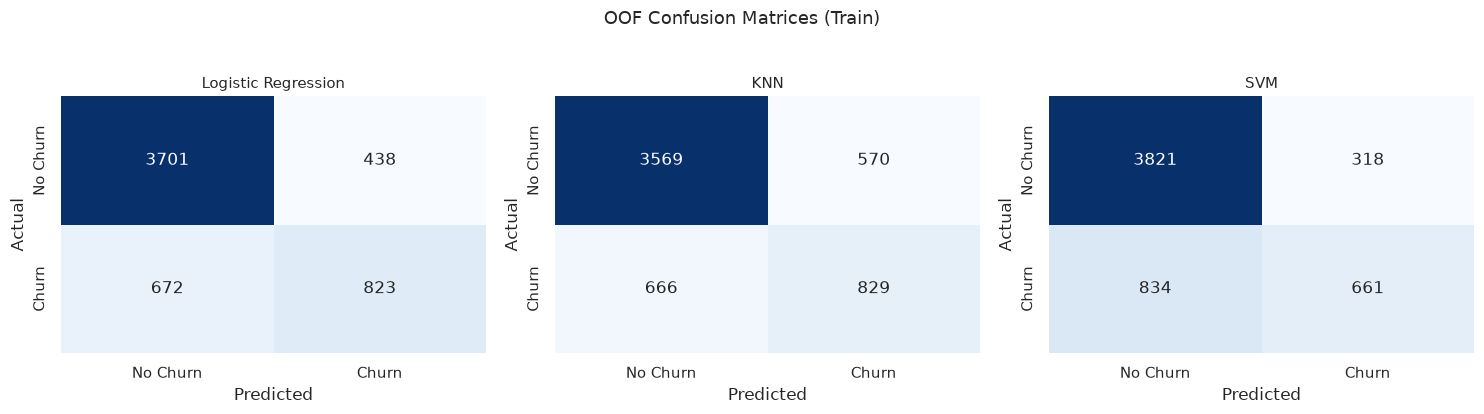

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, preds) in zip(axes, oof_preds.items()):
    cm, cm_norm = plot_confusion_matrix(y_train, preds, f"{name}", ax=ax)
plt.suptitle("OOF Confusion Matrices (Train)", y=1.03, fontsize=13)
plt.tight_layout()
plt.show()
    

**از این نمودارها چه فهمیدیم؟** (تعداد واقعی ریزش‌کننده‌های train برابر ۱٬۴۹۵ است)

* **LR:** TP=823 / FN=672 / FP=438 → نیمی از ریزش‌ها را گرفته، ۴۳۸ مشتری ماندگار را هم بی‌جهت پرچم زده.
* **KNN:** TP=829 / FN=666 / FN تقریباً برابر LR ولی **FP=570** — ۱۳۲ هشدار اضافی بیشتر از LR. یعنی برای همان تعداد ریزشگیری، منابع بیشتری هدر می‌دهد.
* **SVM:** FP فقط **318** (کمترین) ولی FN=**834** — یعنی **۸۳۴ مشتری ریزش‌کننده را رد کرده!** این دقیقاً شکل عددی همان «محافظه‌کاری»‌ای است که گفتیم و نشان می‌دهد چرا فقط به یک معیار اکتفا نکردن مهم است: SVM از نظر FP بهترین است ولی از نظر FN بدترین.

---

### گزارش طبقه‌بندی (Classification Report)
    

In [35]:
for name in oof_preds:
    print_report(y_train, oof_preds[name], title=f"--- {name} (OOF on Train) ---")
    print()
    

--- Logistic Regression (OOF on Train) ---
              precision    recall  f1-score   support

    No Churn      0.846     0.894     0.870      4139
       Churn      0.653     0.551     0.597      1495

    accuracy                          0.803      5634
   macro avg      0.749     0.722     0.733      5634
weighted avg      0.795     0.803     0.797      5634


--- KNN (OOF on Train) ---
              precision    recall  f1-score   support

    No Churn      0.843     0.862     0.852      4139
       Churn      0.593     0.555     0.573      1495

    accuracy                          0.781      5634
   macro avg      0.718     0.708     0.713      5634
weighted avg      0.776     0.781     0.778      5634


--- SVM (OOF on Train) ---
              precision    recall  f1-score   support

    No Churn      0.821     0.923     0.869      4139
       Churn      0.675     0.442     0.534      1495

    accuracy                          0.796      5634
   macro avg      0.748     0

**تفسیر:** دقت کنید به ستون recall کلاس `1` (ریزش): LR و KNN حدود ۵۵٪، SVM حدود ۴۴٪. از طرفی recall کلاس ۰ (ماندگارها) همه بالای ۸۷٪ است — یعنی مدل‌ها در «شناختن ماندگارها» خوب‌اند و همه‌ی سختی در گرفتن ریزش‌کننده‌هاست. همین عدم‌توازن کار را سخت می‌کند و همین است که Accuracy را به معیار اول بدل نمی‌کند: مدلی که روی کلاس ۰ خوب است، بی‌زحمت ۸۰٪ می‌گیرد.

---

### ROC Curve و Precision-Recall Curve

(هر دو از همان امتیازهای OOF ساخته شده‌اند — یعنی بدون هیچ دست‌زدنی به Test.)
    

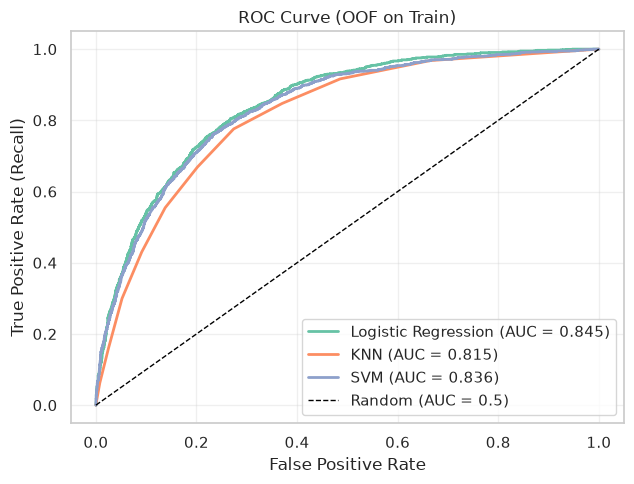

In [36]:
fig = plot_roc_curves(y_train, oof_scores, title="ROC Curve (OOF on Train)")
plt.show()
    

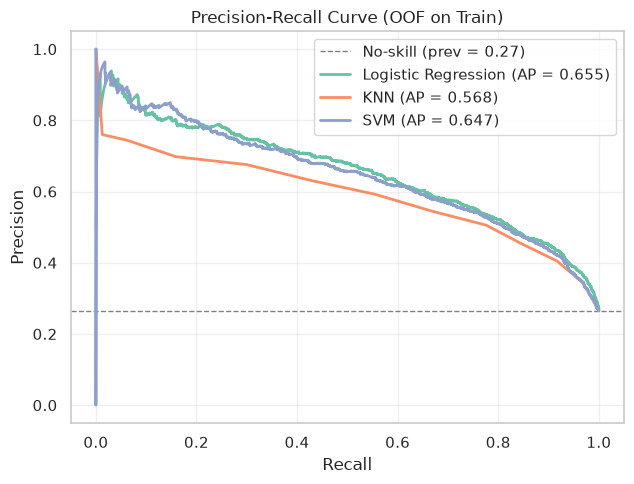

In [37]:
fig = plot_pr_curves(y_train, oof_scores, title="Precision-Recall Curve (OOF on Train)")
plt.show()
    

**از ROC چه فهمیدیم؟**
منحنی هر سه مدل بالاتر از خط نقطه‌چین تصادفی است. LR بالاترین منحنی را دارد (AUC ≈ 0.845)، بعد SVM (≈ 0.836) و بعد KNN (≈ 0.815). یعنی اگر یک ریزش‌کننده و یک ماندگار را تصادفی انتخاب کنیم، LR با احتمال ~۸۴.۵٪ امتیاز ریزش‌کننده را بالاتر می‌گذارد. همچنین دقت کنید همه‌ی منحنی‌ها در گوشه‌ی بالا-چپ «کمال‌گرا» نیستند — مخصوصاً وقتی Recall بالا می‌رویم Precision افت می‌کند؛ یعنی پوشش بیشتر ریسک، با هشدار اشتباه بیشتر همراه می‌شود (قانون بازار!).

**از PR Curve چه فهمیدیم؟**
چون کلاس مثبت نادرتر است، PR curve واقعی‌تر از ROC نشان می‌دهد. خط خاکستری (≈0.27) سطح بدون مهارت است — هر منحنی که بالاتر از آن باشد مفید است. نکته‌ی عملی: مثلاً در Recall≈0.6، Precision حدود 0.6–0.65 است — یعنی اگر بخواهیم ۶۰٪ ریزش‌ها را بگیریم، حدود ۴۰٪ هشدارهایمان اشتباه خواهد بود. این دقیقاً همان چیزی است که تیم کسب‌وکار باید قبل از راه‌اندازی کمپین بداند.
    

## 14. جدول مقایسه مدل‌ها (قبل و بعد از Tuning)

همه‌ی اعداد این جدول از **CV روی Train** می‌آیند — هم‌وزن و مقایسه‌پذیر.
    

In [38]:
comparison_rows = []
for name in ["Logistic Regression", "KNN", "SVM"]:
    before = cv_default_results[name]     # فراپارامترهای پیش‌فرض
    after = tuning_summary[name]          # بعد از GridSearch
    comparison_rows.append({
        "Model": name,
        "Acc (default)": before["accuracy"][0],
        "Acc (tuned)": after["accuracy"],
        "Precision (tuned)": after["precision"],
        "Recall (default)": before["recall"][0],
        "Recall (tuned)": after["recall"],
        "F1 (default)": before["f1"][0],
        "F1 (tuned)": after["f1"],
        "ROC-AUC (default)": before["roc_auc"][0],
        "ROC-AUC (tuned)": after["roc_auc"],
        "Δ F1": after["f1"] - before["f1"][0],
        "Δ ROC-AUC": after["roc_auc"] - before["roc_auc"][0],
    })

comparison_df = pd.DataFrame(comparison_rows).set_index("Model").round(4)
comparison_df
    

,Acc (default),Acc (tuned),Precision (tuned),Recall (default),Recall (tuned),F1 (default),F1 (tuned),ROC-AUC (default),ROC-AUC (tuned),Δ F1,Δ ROC-AUC
Model,,,,,,,,,,,
Logistic Regression,0.8025,0.8030,0.6530,0.5458,0.5505,0.5938,0.5967,0.8457,0.8458,0.0028,0.0001
KNN,0.7685,0.7806,0.5929,0.5371,0.5545,0.5518,0.5730,0.7824,0.8156,0.0211,0.0332
SVM,0.8058,0.7955,0.6771,0.5043,0.4421,0.5796,0.5340,0.8009,0.8365,-0.0456,0.0356


**تفسیر تفاوت‌ها — چرا بعد از tuning عدد‌ها این‌طور تغییر کردند؟**

| مدل | Δ ROC-AUC | Δ F1 | دلیل |
|---|---|---|---|
| **LR** | +0.000 | +0.003 | C=100 انتخاب شد ولی بهبود ناچیز است؛ مدل خطی از اول خوب fit شده بود و ظرفیتش همین‌قدر است. |
| **KNN** | **+0.033** | **+0.021** | K=11 در برابر K=5: همسایه‌های بیشتر → نویز کمتر → بهترین بهبود جدول. |
| **SVM** | **+0.036** | **−0.046** | C=0.1 و gamma=0.01 یعنی مرز نرم‌تر: رتبه‌بندی بهتر شد (AUC ↑) ولی در آستانه‌ی 0.5 محافظه‌کارتر شد (Recall 0.504→0.442، پس F1 پایین آمد). |

این یک درس مهم است: **«بهتر» بستگی به معیار دارد.** ما tuning را با ROC-AUC انجام دادیم؛ SVM از نظر ROC-AUC واقعاً بهتر شد، ولی اگر هدفمان Recall در آستانه‌ی 0.5 بود، همین tuning می‌توانست آن را خراب‌تر کند. وقتی معیار انتخاب مدل را انتخاب می‌کنید، عملاً دارید هدف کسب‌وکار را تعریف می‌کنید.

نکته‌ی دیگر: فاصله‌ی AUC سه مدل بعد از tuning کم شده (0.846 / 0.837 / 0.816) — یعنی بخشی از «ضعف اولیه‌ی KNN و SVM» اصلاً ضعف مدل نبود، **فراپارامتر بد** بود. همین می‌شود که می‌گویند: اول حواست به تنظیمات باشد، بعد بگو مدل ضعیف است.
    

## 15. انتخاب مدل نهایی

### معیار انتخابم چیست؟ (و چه چیزی نیست!)

**فقط بر اساس بیشترین Accuracy انتخاب نمی‌کنم.** اگر همین کار را می‌کردیم، با داده‌های پیش‌فرض، **SVM** برنده می‌شد (Accuracy=0.806 در برابر 0.802 لاجستیک) — در حالی که SVM کلی ریزش‌کننده را جا می‌گذارد. Accuracy با داده‌ی ۷۳/۲۷ و با هزینه‌ی نامتوازنِ FP/FN، معیار درستی نیست.

چهار محور تصمیم من:

1. **Business Goal:** هدف، پیدا کردن ریزش‌کننده‌هاست → Recall و AUC وزن بیشتری دارند.
2. **کیفیت توازن Precision/Recall:** → بهترین F1.
3. **Generalization:** پایداری در foldها (std کوچک) و فاصله‌ی کم train/CV.
4. **Complexity:** بین دو مدل هم‌رده، ساده‌تر و تفسیرپذیرتر برنده است — چون در کسب‌وکار باید بتوانیم تصمیمش را توضیح بدهیم.
    

In [39]:
# رتبه‌بندی نهایی بر اساس معیارات CV (همه‌ی اعداد مال Train است)
ranking = (
    pd.DataFrame(tuning_summary).T
    [["roc_auc", "f1", "recall", "precision", "accuracy"]]
    .rename(columns={"roc_auc": "ROC-AUC", "f1": "F1", "accuracy": "Accuracy"})
    .sort_values("ROC-AUC", ascending=False)
    .round(4)
)
print("رتبه‌بندی بر اساس ROC-AUC (معیار اصلی):")
display(ranking)

best_name = ranking.index[0]
print("=> مدل انتخابی:", best_name)
    

رتبه‌بندی بر اساس ROC-AUC (معیار اصلی):


,ROC-AUC,F1,recall,precision,Accuracy
Logistic Regression,0.845802,0.596687,0.550502,0.653048,0.802984
SVM,0.83655,0.533993,0.44214,0.677087,0.795528
KNN,0.815597,0.572951,0.554515,0.592925,0.780619


=> مدل انتخابی: Logistic Regression


### چرا Logistic Regression؟ (تحلیل صادقانه)

* **بهترین ROC-AUC (0.846):** قوی‌ترین رتبه‌بندی ریسک را دارد — این مهم‌ترین چیزی است که از یک مدل Churn می‌خواهیم، چون در عمل شرکت معمولاً با یک لیست مرتب‌شده کار می‌کند («۵۰۰ مشتری پرریزش هفته‌ی جاری»).
* **بهترین F1 (0.597):** بهترین تعادل Precision/Recall در آستانه‌ی استاندارد.
* **Recall قابل قبول (0.551) در مقابل SVM (0.442):** با هدف «گرفتن ریزش‌کننده‌ها»، SVM نصف ریسک‌ها را رد می‌کند.
* **پایداری:** std کم در CV و فاصله‌ی تقریباً صفر train-CV → overfitting ندارد.
* **سادگی و تفسیرپذیری:** ۴۸ ویژگی یک مجموعه coefficient دارد که می‌شود به تیم محصول نشان داد؛ با RBF-SVM چنین چیزی ممکن نیست. سریع‌ترین مدل هم هست (در production اهمیت دارد).
* **KNN:** AUC پایین‌تر (0.816) و در عمل کندترین predict — کنار می‌رود.
* **SVM:** رقیب جدی AUC (0.837) ولی Recall خام پایین، پیچیدگی بیشتر و تفسیرناپذیری.

نکته‌ی مهم: AUC دو مدل اول خیلی به هم نزدیک‌اند (0.846 در برابر 0.837) — اگر فقط AUC ملاک بود، انتخاب سخت بود. اینجاست که **F1 بالاتر، Recall بسیار بهتر و سادگیِ قابل‌تفسیرِ LR** تعیین‌کننده می‌شود. ضمناً این انتخاب **قبل از دیدن Test** انجام شده — الان دیگر Test را باز می‌کنیم.
    

## 16. ارزیابی نهایی روی Test Set

**یادآوری مهم:** `X_test` از لحظه‌ی split تا همین‌جا دست‌نخورده مانده. هیچ‌کدام از انتخاب‌های بالا (مدل، فراپارامتر، آستانه‌ی 0.5) با دیدن test انجام نشده. الان **تنها لحظه‌ی نگاه کردن** است — و اگر تا اینجا کار درست انجام شده باشد، نتیجه باید به اعداد CV نزدیک باشد.

مدل نهایی = همان `best_estimator_` که GridSearch روی **کل train** refit کرده (با فراپارامترهای `C=100`).
    

In [40]:
final_model = tuned_grids[best_name].best_estimator_
print("مدل نهایی:", best_name)
print("فراپارامترها:", tuned_grids[best_name].best_params_)

test_scores = final_model.predict_proba(X_test)[:, 1]
test_preds = (test_scores >= 0.5).astype(int)

test_metrics = compute_metrics(y_test, test_preds, test_scores)
print("\n=== TEST SET RESULTS ===")
for k, v in test_metrics.items():
    print(f"  {k:10s}: {v:.4f}")
    

مدل نهایی: Logistic Regression
فراپارامترها: {'model__C': 100.0}

=== TEST SET RESULTS ===
  Accuracy  : 0.8048
  Precision : 0.6542
  Recall    : 0.5615
  F1        : 0.6043
  ROC-AUC   : 0.8411


Classification Report (TEST)
              precision    recall  f1-score   support

    No Churn      0.849     0.893     0.870      1035
       Churn      0.654     0.561     0.604       374

    accuracy                          0.805      1409
   macro avg      0.752     0.727     0.737      1409
weighted avg      0.797     0.805     0.800      1409



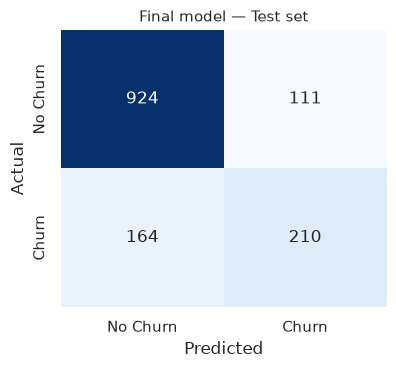

In [41]:
print_report(y_test, test_preds, title="Classification Report (TEST)")

plot_confusion_matrix(y_test, test_preds, "Final model — Test set")
plt.show()
    

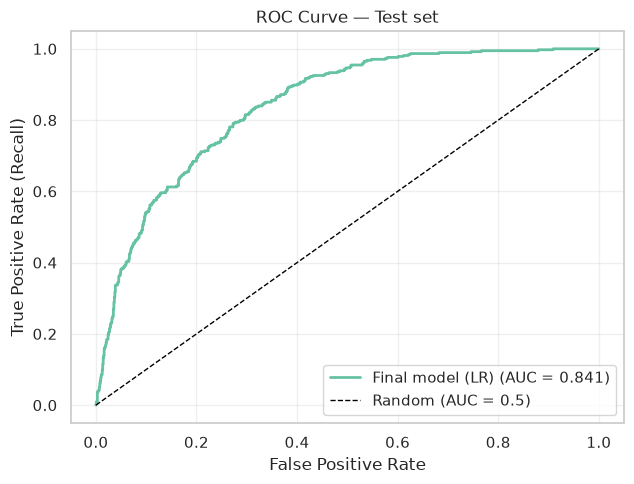

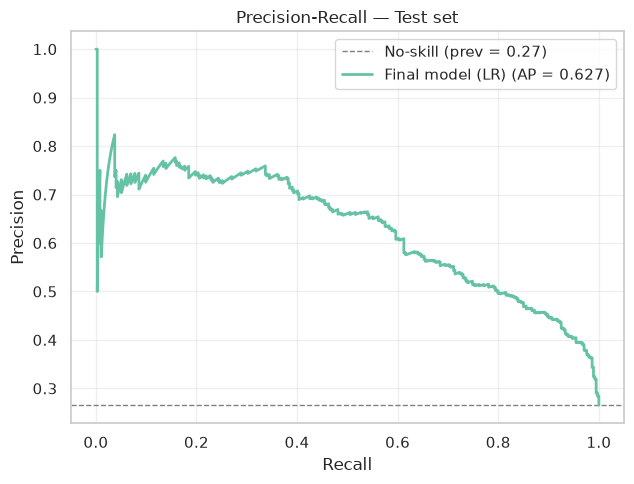

In [42]:
plot_roc_curves(y_test, {"Final model (LR)": test_scores}, title="ROC Curve — Test set")
plt.show()

plot_pr_curves(y_test, {"Final model (LR)": test_scores}, title="Precision-Recall — Test set")
plt.show()
    

### تحلیل نتیجه‌ی نهایی

**اعداد Test:** Accuracy = **0.805**، Precision = **0.654**، Recall = **0.561**، F1 = **0.604**، ROC-AUC = **0.841**

1. **اعتبارسنجی کل پروژه:** نتایج test تا چه حد به CV نزدیک است؟ Accuracy: 0.805 در برابر 0.803 و AUC: 0.841 در برابر 0.846 — اختلاف ≤ 0.005. این یعنی انتخاب مدل و tuning درست انجام شده و **مدل generalization واقعی دارد** (اگر test خیلی پایین‌تر بود، نشانه‌ی overfitting یا leakage بود).

2. **شکست‌ها را هم باید ببینیم:** Confusion Matrix می‌گوید از ۳۷۴ ریزش‌کننده‌ی واقعی test، **۲۱۰ تا را گرفتیم و ۱۶۴ تا را از دست دادیم** (FN). یعنی مدل نهایی در حالت آستانه‌ی 0.5، **حدود ۴۴٪ ریزش‌ها را هشدار نمی‌دهد**. همچنین ۱۱۱ مشتری ماندگار را اشتباهی پرچم زده (FP) — یعنی به ۱۱۱ نفر بی‌جهت پیشنهاد Retention می‌رود.

3. **در برابر Baseline:** مدل پایه صفر ریزش‌کننده می‌گرفت؛ مدل نهایی **۲۱۰ تا** را گرفت و F1 از 0.0 به **0.604** رسید. این فاصله، ارزش کل پروژه است.

4. **تحلیل Precision:** وقتی مدل می‌گوید «این مشتری می‌رود»، با احتمال **۶۵.۴٪** درست می‌گوید — یعنی از هر ~۳ هشدار، ۲ تا واقعاً درست است. برای شروع کمپین Retention قابل قبول است.

**و اگر بخواهیم Recall را بیشتر کنیم؟** آستانه‌ی 0.5 یک انتخاب پیش‌فرض است، نه وحی‌آسمانی. با پایین آوردن آستانه، Recall بالا می‌رود و Precision پایین — این تبادل را در بخش کسب‌وکار با عدد نشان می‌دهم.
    

## 17. تفسیر مدل (Model Interpretation)

### آیا مدل را می‌شود توضیح داد؟

بله — و این یکی از دلایل انتخاب Logistic Regression بود. در LR هر ویژگی یک **coefficient** دارد؛ علامتش جهت اثر را می‌گوید (مثبت → احتمال ریزش بیشتر) و اندازه‌اش شدت اثر را، **به شرطِ ثابت بودن بقیه‌ی ویژگی‌ها**. چون ویژگی‌ها scaling شده‌اند، اندازه‌ی coefficientها با هم قابل مقایسه‌اند.

(اگر مدل نهایی SVM با kernel غیرخطی بود، چنین جدولی نداشتیم — آنجا باید سراغ Permutation Importance یا SHAP می‌رفتیم. برای همین سادگی را دوست دارم.)
    

In [43]:
feature_names = final_model.named_steps["preprocess"].get_feature_names_out()
coefficients = final_model.named_steps["model"].coef_.flatten()

coef_series = pd.Series(coefficients, index=feature_names)
coef_df = pd.DataFrame({
    "coefficient": coef_series,
    "odds_ratio": np.exp(coef_series),          # هر 1 واحد std چند برابر شانس ریزش
}).sort_values("coefficient", ascending=False)

print("=== 10 ویژگی با بیشترین اثر مثبت (افزایش ریزش) ===")
display(coef_df.head(10).round(3))
print("=== 10 ویژگی با بیشترین اثر منفی (کاهش ریزش) ===")
display(coef_df.tail(10).round(3))
    

=== 10 ویژگی با بیشترین اثر مثبت (افزایش ریزش) ===


,coefficient,odds_ratio
cat__InternetService_Fiber optic,1.288,3.626
num__ServicesCount,0.625,1.868
num__TotalCharges,0.576,1.779
cat__Contract_Month-to-month,0.555,1.742
cat__MultipleLines_Yes,0.351,1.420
cat__StreamingTV_Yes,0.324,1.382
cat__StreamingMovies_Yes,0.323,1.381
cat__OnlineSecurity_No,0.258,1.294
cat__TechSupport_No,0.230,1.258
num__AvgMonthlyCharge,0.200,1.221


=== 10 ویژگی با بیشترین اثر منفی (کاهش ریزش) ===


,coefficient,odds_ratio
cat__OnlineSecurity_No internet service,-0.499,0.607
cat__InternetService_No,-0.499,0.607
cat__StreamingMovies_No internet service,-0.499,0.607
cat__StreamingTV_No internet service,-0.499,0.607
cat__OnlineBackup_No internet service,-0.499,0.607
cat__DeviceProtection_No internet service,-0.499,0.607
cat__Contract_Two year,-0.822,0.440
cat__InternetService_DSL,-1.200,0.301
num__tenure,-1.299,0.273
num__MonthlyCharges,-2.245,0.106


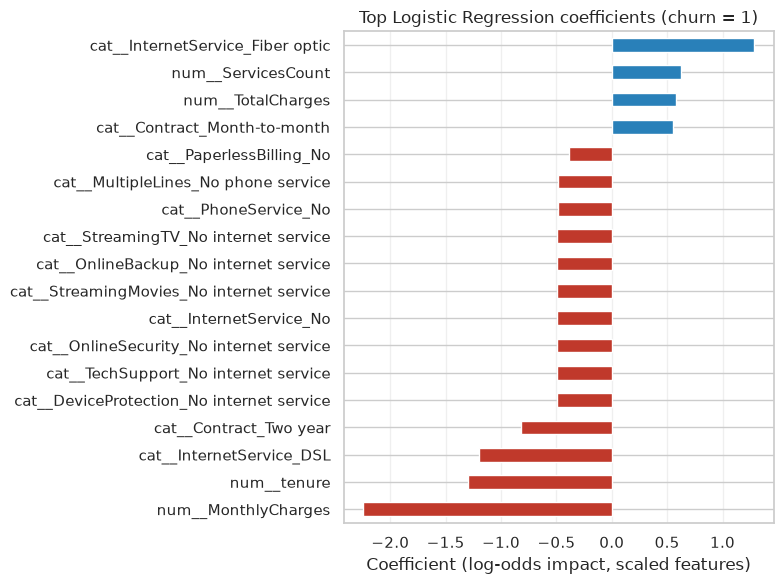

In [44]:
from src.evaluate import plot_coefficients
plot_coefficients(feature_names, coefficients, top_n=18,
                  title="Top Logistic Regression coefficients (churn = 1)")
plt.show()
    

### از coefficientها چه فهمیدیم؟ و آیا منطقی‌اند؟

**مهم‌ترین عوامل ریزش (coefficients مثبت):**

1. **`InternetService_Fiber optic` (+1.29)** — قوی‌ترین سیگنال؛ با EDA کاملاً هم‌خوان است (فیبر ۴۲٪ ریزش).
2. **`Contract_Month-to-month` (+0.56)** — همان داستان قرارداد ماهانه.
3. **`ServicesCount` و `TotalCharges` (+0.63، +0.58)** — بارِ خدمات/مالی.
4. **نبود پشتیبانی فنی/امنیت (`TechSupport_No`, `OnlineSecurity_No`)** — کسی که این افزونه‌ها را ندارد ریسک بالاتری دارد.

**مهم‌ترین عوامل ماندگاری (coefficients منفی):**

1. **`MonthlyCharges` (−2.25)** — جالب و ظریف!
2. **`tenure` (−1.30)** — هر ماه همکاری بیشتر، ریسک کمتر (سازگار با EDA).
3. **`Contract_Two year` (−0.82)** و **`InternetService_DSL` (−1.20)**.

**آیا نتایج منطقی‌اند؟ بله، ولی دو نکته‌ی هوشمندانه:**

* **سازگاری با EDA:** قرارداد دوساله، tenure بالا، DSL/بدون اینترنت همه در جهتی هستند که از نمودارها فهمیدیم — یعنی مدل چیز خیالی یاد نگرفته.
* **چرا `MonthlyCharges` ناگهان منفی شد؟** در EDA، قیمت بالاتر با ریزش بیشتر هم‌بسته بود (correlation مثبت). اینجا اما وقتی `AvgMonthlyCharge` و `TotalCharges` و `ServicesCount` هم در مدل هستند، coefficient به **شرطی** از آب درمی‌آید: «برای دو مشتری با میانگین پرداخت و قرارداد و سابقه‌ی **یکسان**، کسی که قیمت فعلی‌اش بالاتر از میانگین خودش است کمتر می‌رود.» این دقیقاً به‌خاطر **Multicollinearity** (هم‌بستگی بین خودِ ویژگی‌ها) است — نشانه‌ی اینکه coefficient را هیچ‌وقت به‌تنهایی و بدون توجه به بقیه‌ی ویژگی‌ها تفسیر نکنیم. (این همان چیزی است که Correlation ≠ Causation را در عمل نشان می‌دهد.)

**اختیاری — SHAP:**
اگر بخواهیم برای هر **مشتریِ تکی** بگوییم «چرا این فرد پرریزش است؟» (مثلاً در پنل Retention)، می‌توانیم SHAP را اضافه کنیم: `shap.Explainer(final_model)` برای هر پیش‌بینی، سهم هر ویژگی را نسبت به پایه برمی‌گرداند. اینجا عمداً اضافه نکردم تا پروژه سنگین نشود — ولی راه توسعه‌ی آن باز است (بخش 20).
    

## 18. تفسیر کسب‌وکاری (Business Interpretation)

### مدل با این اعداد در عمل چه می‌کند؟

فرض کن هفته‌ای یک بار مدل روی همه‌ی مشتریان اجرا می‌شود و لیستی از «مشتریان پرریزش» به تیم Retention می‌دهد. در Test Set این یعنی:

* از **۳۷۴ مشتری واقعاً ریزش‌کننده، ۲۱۰ تا (۵۶٪)** در لیست بودند → برای این ۲۱۰ نفر می‌شود **قبل از لغو اشتراک** پیشنهاد فرستاد: تخفیف تمدید، بسته‌ی ارزان‌تر، تماس پشتیبانی. حتی اگر فقط **۲۰–۳۰٪** این پیشنهادها جواب بدهد، ده‌ها مشتری نجات پیدا کرده که بدون مدل، بی‌صدا رفته بودند.
* **۱۶۴ نفر (۴۴٪)** از قلم افتادند (FN) — این سقف بهبود کار ماست و دلیل اینکه در بهبودهای آینده سراغ Recall بالاتر می‌رویم.
* **۱۱۱ نفر اشتباهی در لیست بودند** (FP) — به این‌ها پیشنهاد می‌رود در حالی که قرار نبود بروند.

### هزینه‌ی FP در برابر FN (تحلیل هزینه)

| خطا | چه اتفاقی می‌افتد؟ | هزینه (فرض سرانگشتی) |
|---|---|---|
| **FP** (پرچم اشتباه) | به مشتری ماندگار پیشنهاد تخفیف می‌دهیم | هزینه‌ی کمپین، مثلاً ۱۰–۲۰ دلار به ازای هر نفر. بدترین حالت: تخفیفی که لازم نبود بدهیم. |
| **FN** (ریزشِ ندیده) | مشتری می‌رود و ما نمی‌فهمیم | **کل درآمد آینده‌ی او از دست می‌رود** (مثلاً ~۶۰ دلار × ده‌ها ماه ≈ صدها تا هزاران دلار LTV) + هزینه‌ی جذب مشتری جدید برای جایگزینی‌اش. |

یعنی **هزینه‌ی FN معمولاً ده‌ها برابر FP است**. پس تحمل FP بالاتر، توجیه اقتصادی دارد — و همین ما را به سمت Recall بالاتر و آستانه‌ی پایین‌تر می‌برد:

### آستانه (Threshold) یک ابزار کسب‌وکار است

(این جدول با پیش‌بینی‌های OOF روی **Train** ساخته شده — باز هم Test دست‌نخورده است؛ فقط داریم نشان می‌دهیم اگر تیم کسب‌وکار آستانه را جابه‌جا کند چه می‌شود.)
    

In [45]:
threshold_rows = []
for t in [0.3, 0.4, 0.5, 0.6]:
    m = compute_metrics(y_train, (oof_scores[best_name] >= t).astype(int), oof_scores[best_name])
    threshold_rows.append({"Threshold": t, **{k: round(v, 3) for k, v in m.items()}})
threshold_df = pd.DataFrame(threshold_rows).set_index("Threshold")
threshold_df
    

,Accuracy,Precision,Recall,F1,ROC-AUC
Threshold,,,,,
0.3,0.764,0.539,0.767,0.633,0.845
0.4,0.791,0.595,0.662,0.627,0.845
0.5,0.803,0.653,0.551,0.597,0.845
0.6,0.797,0.712,0.397,0.509,0.845


**از این جدول چه فهمیدیم؟**

* آستانه‌ی **0.5** (پیش‌فرض): Accuracy=0.803، Recall=0.551 — تعادل خوب ولی ۴۵٪ ریزش‌ها را می‌گیرد.
* آستانه‌ی **0.3**: Accuracy به **0.764 می‌رود (پایین‌تر!)** ولی Recall به **0.767** — یعنی **سه‌چهارم ریزش‌کننده‌ها را می‌گیریم** به قیمت اینکه هشدارهای اشتباه بیشتر شوند (Precision از 0.653 به 0.539).

**این دقیقاً پاسخ این سؤال است که «چرا مدل با Accuracy کمتر ممکن است برای کسب‌وکار بهتر باشد؟»** — شرکتی که هدفش نجات مشتری است، با خوشحالی ۴ درصد Accuracy را فدای ۲۰ درصد Recall می‌کند، چون هر درصد Recall یعنی ده‌ها مشتری واقعی بیشتر که می‌شود قبل از رفتن با او حرف زد. Accuracy فقط می‌گوید «کلی درست گفتی»؛ به ما نمی‌گوید *کدام* اشتباه‌ها را کرده‌ایم.

**جمع کسب‌وکاری:** مدل نهایی با ROC-AUC≈0.84 یک ابزار غربالگری قابل قبول است: به تیم Retention می‌گوید «کجا را نگاه کنند» و با تنظیم آستانه، سخت‌گیری کمپین قابل تنظیم است. اما این یک **سیگنال پیش‌بینی است، نه حکم قطعی** — تصمیم نهایی همیشه با انسان است.
    

## 19. محدودیت‌ها (Limitations)

صادقانه، چیزهایی که این پروژه **نیست** یا درست انجام نمی‌دهد:

1. **Dataset نماینده‌ی واقعیت نیست.** Telco Churn یک داده‌ی نمونه‌ی عمومی از IBM است؛ مشتریان واقعی شرکت ما ممکن است رفتار متفاوتی داشته باشند (بازار، قیمت‌ها، رقبا فرق دارند). نتایج باید روی داده‌ی خود شرکت دوباره سنجیده شوند.
2. **رفتار مشتری در آینده تغییر می‌کند (Concept Drift).** مدل روی داده‌های گذشته یاد گرفته؛ اگر شرکت قیمت‌ها را عوض کند یا رقیب جدید بیاید، همان مشتری‌ها الگوی دیگری پیدا می‌کنند. مدل باید دوره‌ای retrain شود.
3. **Correlation ≠ Causation.** مدل می‌گوید «فیبر با ریزش هم‌بسته است»، نه اینکه «فیبر علت ریزش است». تفسیر علّی نیاز به آزمایش کنترل‌شده دارد.
4. **مدل تضمین نمی‌کند مشتری حتماً برود.** خروجی یک احتمال است (مثلاً 0.7)، نه سرنوشت محتوم. حتی FN هم معنایش «احتمال بالا بود ولی نرفت/ما نفهمیدیم» است.
5. **کیفیت مدل وابسته به کیفیت داده است.** اگر برچسب‌ها خطا داشته باشند (مثلاً کسی رفت و ثبت نشده)، مدل همان خطا را یاد می‌گیرد — garbage in, garbage out.
6. **آستانه‌ی 0.5 بهینه نیست** (در بخش 18 دیدیم) و ما آن را بهینه‌سازی نکردیم — چون بهینه‌سازی آستانه باید با هزینه‌های واقعی کسب‌وکار انجام شود.
7. **دقت برچسب‌های EDA ما توصیفی است**؛ مثلاً تفاوت Electronic check شاید به سن/منطقه مربوط باشد که در داده نداریم (Covariate آشکار نیست).
    

## 20. بهبودهای آینده (Future Improvements)

این‌ها را **عامدانه داخل پروژه نیاوردم** تا پروژه‌ی اصلی ساده و قابل دفاع بماند؛ ولی مسیرهای کاملاً واقعی برای ادامه‌اند:

**مدل‌سازی**
* **Random Forest / Gradient Boosting (XGBoost, LightGBM):** معمولاً ۱–۳ درصد AUC بیشتر می‌دهند و روابط غیرخطی را خودکار می‌گیرند؛ اولین گام منطقی بعدی.
* **Ensemble:** ترکیب Voting/Stacking از همین سه مدل (به‌خصوص LR که خطی است + یک مدل درختی) معمولاً پایداری بیشتری می‌آورد.
* **Class Weighting:** به مدل گفتن که «اشتباهِ ریزش‌کننده ۵ برابر مهم‌تر است» (`class_weight='balanced'`) — به‌جای دستکاری داده.
* **Threshold Optimization:** بهینه‌سازی آستانه بر اساس منحنی هزینه‌ی واقعی (بخش 18 نقطه‌ی شروع است).
* **Cost-sensitive Learning:** تبدیل مستقیم هزینه‌های FP/FN به معیار آموزش.

**تفسیر**
* **SHAP / LIME:** تفسیر per-customer برای پنل Retention.
* **Feature Engineering بیشتر:** تعامل‌ها (مثلاً tenure × Contract)، روند پرداخت در ماه‌های اخیر، نرخ تغییر سرویس.

**عملیاتی**
* **Deployment به‌صورت API:** یک سرویس FastAPI که مدل سریالایزشده را لود می‌کند و با هر درخواست `predict` می‌دهد (کد آماده‌ی ذخیره‌ی مدل از همین‌جا با `src/utils.save_model` موجود است).
* **Retrain دوره‌ای + مانیتورینگ drift** و A/B test کردن کمپین‌های Retention.

(باز هم تأکید: هیچ‌کدام از این‌ها شرط قبولی یا کامل بودن این پروژه نیستند؛ پروژه با همین سه خانواده‌ی مدل و رعایت methodology درست، یک چرخه‌ی کامل ML است.)
    

## 21. جمع‌بندی نهایی (Final Conclusion)

**مسئله:** پیش‌بینی ریزش مشتریان یک سرویس اشتراکی، برای اینکه شرکت بتواند قبل از لغو اشتراک، مداخله‌ی Retention انجام دهد.

**Dataset:** Telco Customer Churn از IBM — ۷٬۰۴۳ سطر، ۲۱ ستون، نرخ ریزش ۲۶.۵٪ (کلاس نامتوازنِ ملایم)، بدون تکرار کامل و با ۱۱ مقدار خالی در `TotalCharges` (که همه تازه‌وارد بودند).

**مهم‌ترین یافته‌های EDA:**
* قرارداد ماهانه با ۴۲.۷٪ ریزش، قوی‌ترین سیگنال (در برابر ۲.۸٪ قرارداد دوساله)
* شش ماه اول پرریزش‌ترین دوره است
* فیبر نوری (۴۱.۹٪) و Electronic check (۴۵.۳٪) پرریزش‌ترین سطوح‌اند
* مشتریان ریزش‌کننده در ماه ۷۴ دلار می‌پرداختند در برابر ۶۱ دلار ماندگارها

**مدل‌های بررسی‌شده:** Baseline (Dummy) + Logistic Regression + KNN + SVM — همه با Stratified 5-Fold CV و GridSearch.

**بهترین Hyperparameterها:**
| مدل | بهترین تنظیم | AUC بعد از tuning |
|---|---|---|
| **Logistic Regression** | `C=100` | **0.846** |
| SVM | `C=0.1, gamma=0.01, kernel=rbf` | 0.837 |
| KNN | `n_neighbors=11, weights=uniform, p=2` | 0.816 |

**بهترین مدل:** **Logistic Regression** — نه به‌خاطر Accuracy، بلکه به‌خاطر بهترین ROC-AUC و F1، Recall بالاتر نسبت به SVM، پایداری در CV، سادگی و تفسیرپذیری.

**معیارهای نهایی (روی Test، تنها یک بار):**

| Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|
| **0.805** | **0.654** | **0.561** | **0.604** | **0.841** |

و چون به CV (0.803 / 0.846) بسیار نزدیک است، generalization تأیید شده.

**مهم‌ترین Featureها (از coefficientهای LR):** `InternetService_Fiber optic` و `Contract_Month-to-month` بزرگ‌ترین عوامل ریزش؛ `tenure` و `Contract_Two year` و قیمت فعلی پایین‌تر، بزرگ‌ترین عوامل ماندگاری — کاملاً سازگار با EDA.

**نتیجه‌ی کسب‌وکاری:** با این مدل، شرکت می‌تواند **~۵۶٪ مشتریان در معرض ریزش را شناسایی و قبل از رفتن با آن‌ها تماس بگیرد** (در تست: ۲۱۰ از ۳۷۴ نفر)، و با پایین آوردن آستانه تا 0.3 تا ~۷۷٪ هم پوشش را بالا ببرد — به قیمت هشدارهای اشتباه بیشتر. این تبادل را حالا تیم کسب‌وکار است که با اعداد جلوی چشمش باید تصمیم بگیرد.
    

## 22. اگر استاد ازم سؤال بپرسد

**۲۴ سؤال احتمالی + جواب کوتاه:**

**۱. چرا این Dataset؟**
چون هم عمومی و قابل ارجاع است (IBM Telco Churn)، هم دقیقاً همان ساختار مسئله‌ی کسب‌وکاریِ ما را دارد (چند دسته ویژگی + target دودویی)، هم اندازه‌اش برای یادگیری کلاسیک مناسب است و هم دغدغه‌های واقعی داده (مقادیر گم‌شده، ناهماهنگی نوع‌ها، کلاس نامتوازن) را برای تمرین پاک‌سازی دارد.

**۲. چرا Classification؟ چرا Regression نشد؟**
چون خروجی دسته‌ای است (می‌رود/نمی‌رود). اگر می‌خواستیم «چقدر احتمال دارد در ۶ ماه آینده برود» را به‌صورت احتمال پیوسته و پشت‌سرهم تخمین بزنیم یا «مبلغ سال آینده» را، می‌شد Regression. هدف ما تصمیم دسته‌ای است.

**۳. چرا Accuracy به‌تنهایی کافی نیست؟**
چون با ۷۳/۲۷ نامتوازن، مدل «همه را No» بدون هیچ یادگیری ۷۳.۵٪ می‌گیرد و در عین حال **هیچ** ریزش‌کننده‌ای را نمی‌گیرد (Recall=0). Accuracy نمی‌گوید کدام خطا را مرتکب شده‌ای؛ در Churn که هزینه‌های FP و FN فرق دارند، این کافی نیست.

**۴. چرا Scaling لازم است؟**
چون مقیاس ویژگی‌ها فرق دارد (مثلاً TotalCharges تا ۸۰۰۰ در برابر ServicesCount تا ۶). بدون scaling، ویژگی‌های بزرگ‌مقیاس همه‌چیز را می‌بلعند. برای KNN و SVM که با distance کار می‌کنند اصلاً بدون scaling معنا ندارد؛ برای LR هم کمک به همگرایی و مقایسه‌پذیری coefficientها می‌کند.

**۵. چرا KNN به Scaling حساس است؟**
چون تصمیمش ۱۰۰٪ بر اساس فاصله است: «K تا نزدیک‌ترین همسایه». اگر یک ستون بزرگ‌مقیاس باشد، فاصله‌ی همه تقریباً فقط به آن ستون می‌شود و بقیه ویژگی‌ها عملاً نادیده گرفته می‌شوند.

**۶. SVM چگونه کار می‌کند؟**
دنبال مرز تصمیمی می‌گردد که **margin** (فاصله‌ی امن بین دو کلاس) را بیشینه کند؛ داده‌های نزدیک مرز Support Vector نامیده می‌شوند و فقط آن‌ها مرز را تعیین می‌کنند. اگر خط ساده کافی نباشد، با **kernel** فضا را می‌برد بالاتر تا در آنجا قابل جدا شدن باشد.

**۷. C چیست؟ (در LR و SVM)**
پارامتر کنترلِ trade-off بین سادگی و خطا: C کوچک = regularization شدید = مرز/وزن نرم‌تر ( risking underfitting)، C بزرگ = مجازات کم = چسبیدن به داده‌ی train ( risking overfitting).

**۸. Gamma چیست؟**
فقط در kernelهایی مثل rbf: محدوده‌ی نفوذ هر نقطه. gamma بزرگ = نفوذ کوتاه = مرز پیچیده و چسبیده به داده (خطر overfitting)؛ gamma کوچک = نفوذ گسترده = مرز نرم.

**۹. Kernel چیست؟**
ترفندی برای تفکیک داده‌های غیرخطی با پرتابشان به فضای بعد بالاتر — بدون محاسبه‌ی صریح آن فضا (kernel trick). رایج: linear و rbf.

**۱۰. Parameter و Hyperparameter چه فرقی دارند؟**
Parameter (مثل وزن LR) را خود مدل حین training یاد می‌گیرد؛ Hyperparameter (مثل C یا K) را ما قبل از training دستی تنظیم می‌کنیم و با GridSearch می‌جوییم.

**۱۱. Cross Validation چیست و چرا؟**
چند بار تقسیم‌بندی train و میانگین گرفتن از نتایج، تا امتیاز به شانسِ یک split خاص وابسته نباشد و تخمین پایدارتری از عملکرد روی داده‌ی نو بدهد.

**۱۲. چرا Stratified K-Fold؟**
چون کلاس‌ها نامتوازن‌اند؛ Stratified تضمین می‌کند نسبت ریزش در هر fold مثل کل داده بماند، تا بعضی foldها بی‌دلیل ریزش‌کننده کم/زیاد نداشته باشند و معیارها قرینه بمانند.

**۱۳. Data Leakage چیست و چطور جلوگیری کردی؟**
یعنی اطلاعاتی که در لحظه‌ی پیش‌بینی در دسترس نیست یا از target می‌آید، وارد فرایند یادگیری شود. من: (۱) preprocessing را داخل Pipeline گذاشتم تا فقط روی train هر fold fit شود، (۲) تست را تا آخر باز نکردم، (۳) ویژگی‌های جدید را فقط از تاریخچه ساختم نه از برچسب.

**۱۴. چرا Test Set را فقط آخر استفاده کردیم؟**
چون هر نگاه و هر تصمیم بر اساس آن، کمی اطلاعات از test به فرایند انتخاب نشت می‌دهد و امتیاز نهایی را خوش‌بینانه می‌کند. مثل اینکه جواب امتحان را از استاد بگیری و بعد بگویی «من بلد بودم!».

**۱۵. Precision و Recall چه فرقی دارند؟**
Precision: از هر چه مدل «ریزش» اعلام کرده، چقدر واقعاً ریزش بوده؟ (اعتماد به هشدار). Recall: از کل ریزش‌های واقعی، چقدر را گرفته‌ایم؟ (پوشش ریسک). یکی به بی‌خطر بودن هشدار نگاه می‌کند، دیگری به نگذشتن خطر.

**۱۶. False Positive و False Negative کدام‌اند و کدام مهم‌تر؟**
FP = گفت می‌رود ولی نرفت (کمپین هدررفته). FN = گفت نمی‌رود ولی رفت (مشتری از دست رفته). در Churn معمولاً FN خیلی گران‌تر است، پس Recall اولویت دارد — مگر اینکه بودجه‌ی کمپین خیلی محدود باشد که آن‌وقت Precision مهم‌تر می‌شود.

**۱۷. چرا مدل نهایی را Logistic Regression انتخاب کردی؟**
بالاترین ROC-AUC (0.846) و F1 (0.597) در CV، در برابر SVM با Recall خیلی پایین‌تر (0.442) و KNN با AUC پایین‌تر؛ به‌علاوه پایدارترین، ساده‌ترین و تنها مدلی که coefficientهای قابل تفسیر دارد. و همه‌ی این‌ها **قبل از** دیدن test تصمیم‌گیری شد.

**۱۸. اگر داده‌ها بیشتر شوند چه می‌شود؟**
معمولاً به خصوص KNN و SVM (و هر مدل عمیق‌تر) کمک می‌کند؛ تخمین CV هم پایدارتر می‌شود. ولی افزایش حجم جای کیفیت (برچسب درست، ویژگی‌های مناسب) را نمی‌گیرد — داده‌ی بیشتر با همان کیفیت، نه لزوماً جهش عملکرد.

**۱۹. اگر Class Imbalance شدیدتر شود چه می‌کنی؟**
چند گزینه: `class_weight='balanced'` (مجازات نامتوازن)، undersampling/oversampling (مثل SMOTE)، تغییر آستانه، و تأکید بر AUC/F1/PR-AUC به‌جای Accuracy. اینجا imbalance ملایم بود و با stratify و معیارهای مناسب کنار آمدیم.

**۲۰. مدل را چطور در Production می‌گذاری؟**
مدلِ fit شده را با joblib ذخیره می‌کنم (`src/utils.save_model`)، پشت یک API (FastAPI/Flask) می‌گذارم که همان pipeline را لود کند (یعنی preprocessing هم داخل خود مدل است و جدا اجرا نمی‌شود)، ورودی JSON می‌گیرد و امتیاز ریزش برمی‌گرداند؛ بعدش مانیتورینگ drift و retrain دوره‌ای.

**۲۱. Margin یعنی چه؟**
فاصله‌ی بین مرز تصمیم و نزدیک‌ترین داده‌ها. SVM مرزی با بیشینه‌ی margin می‌خواهد چون «حاشیه‌ی امن» بیشتر = احتمال خطای کمتر روی داده‌ی جدید.

**۲۲. Regularization چیست؟ چرا لازم است؟**
مجازاتِ سادگیِ مدل: جلوی وزن‌های بزرگ و پیچیدگی بیش از حد را می‌گیرد تا مدل به جای حفظ نویز train، الگوی کلی را یاد بگیرد. در LR با C و در SVM با C کنترل می‌شود.

**۲۳. Overfitting را چطور تشخیص دادی؟**
مقایسه‌ی امتیاز train با CV: KNN اینجا صفر تفاوت نشان نداد — train ≈ 1.0 در برابر CV ≈ 0.77 یعنی Overfitting آشکار. LR با فاصله‌ی تقریباً صفر سالم است. نشانه‌ی دیگر: فاصله‌ی زیاد بین train و test در پایان کار.

**۲۴. چرا tuning را با ROC-AUC انجام دادی نه Recall؟**
چون ROC-AUC به آستانه وابسته نیست و کل توانایی رتبه‌بینی مدل را می‌سنجد؛ اگر روی Recall تنها بهینه می‌کردیم، مدل می‌توانست با آستانه‌ی پایین همه را «ریزش» اعلام کند و Recall ظاهری بالا بیاورد بی‌آنکه واقعاً بهتر شده باشد. آستانه‌ی عملیاتی را مرحله‌ی بعد (بخش 18) با نگاه هزینه تنظیم می‌کنیم.
    

## 23. چیزهایی که باید خودم بتوانم توضیح بدهم

اگر بخواهم خلاصه کنم، این‌ها مواردی‌اند که واقعاً باید بلد باشم — نه اینکه فقط کدشان را نوشته باشم:

**مبانی مسئله**
- [ ] تفاوت Classification و Regression و اینکه چرا اینجا Classification است
- [ ] Feature ، Target و اینکه چرا `customerID` ویژگی نیست
- [ ] چرا Accuracy با کلاس نامتوازن گمراه‌کننده است (و مثال «همه را No»)

**داده**
- [ ] چه چیزهایی را در شناخت داده چک کردم و چرا (missing/duplicate/ناهمنطقی/تایپ/توزیع target)
- [ ] تصمیم‌هایم در پاک‌سازی و **دلیل هر کدام** (چرا خالی‌ها را 0 کردم نه میانه؟ چرا duplicate را نگه داشتم؟)
- [ ] هر ویژگی جدید چه چیزی اضافه می‌کند و **چرا Leakage نیست**

**روش‌شناسی**
- [ ] نقش Train / Validation / Test و اینکه چرا Test فقط آخر
- [ ] Overfitting و Underfitting — و نشانه‌های عددی‌شان (مقایسه train با CV)
- [ ] Pipeline و ColumnTransformer — چه دردی را درمان می‌کنند (leakage + بهداشت کد)
- [ ] Encoding (چرا One-Hot نه Label برای چنددسته‌ای) و Scaling (چرا برای KNN/SVM حیاتی)
- [ ] Cross Validation ، Stratified K-Fold و مفهوم K
- [ ] Parameter در برابر Hyperparameter و Grid Search

**مدل‌ها**
- [ ] intuition هر سه مدل با زبان خودم: LR = امتیاز خطی + سیگموید؛ KNN = رأی همسایه‌ها؛ SVM = حداکثر margin
- [ ] C ، gamma ، kernel ، n_neighbors و اینکه هر کدام اگر زیاد/کم شود چه می‌شود
- [ ] چرا بهترین SVM اینجا Recall پایین آورد (تغییر معیار = تغییر «بهتر»)

**ارزیابی و تفسیر**
- [ ] معنای عددی Precision/Recall/F1 با مثال واقعی همین پروژه
- [ ] خواندن Confusion Matrix و پیدا کردن TP/FP/FN/TN
- [ ] ROC-AUC چه می‌گوید و چرا به آستانه وابسته نیست
- [ ] تفاوت هزینه‌ی FP و FN در کسب‌وکار و اینکه چرا آستانه 0.5 مقدس نیست
- [ ] خواندن coefficientهای LR — و اینکه چرا `MonthlyCharges` اینجا منفی شد (multicollinearity / اثر شرطی)
- [ ] نتیجه‌ی نهایی را با یک جمله‌ی کسب‌وکاری توضیح بدهم: «مدل X٪ از ریزش‌های واقعی را قبل از وقوع شناسایی می‌کند»

اگر این ۲۰ تا را بتوانم بدون نگاه کردن به نوت‌بوک توضیح بدم، پروژه واقعاً مالِ خودم است.
    

---
**پایان نوت‌بوک** — تمام کدها قابل اجرا و reproducible هستند (random_state=42)؛ کتابخانه‌های قابل استفاده‌ی مجدد در `src/` جدا شده‌اند.
    